# Dunnhumby "The Complete Journey": in-depth EDA and data preparation

**Project:** Segment-aware demand transference modelling for store-level assortment rationalisation in grocery retail
**Author:** Neha Amudapuram (25109936), MSc Data Analytics, NCI

This notebook extends the basic EDA (`dunhumbybasic.ipynb`). The basic notebook covered scale, cleaning of non-positive quantities, department mix and demographic coverage. This notebook goes on to everything the modelling stages need:

| Part | What it does | Feeds stage |
|---|---|---|
| 1 | Setup and configuration | all |
| 2 | Data-quality audit and cleaning rules, with a row waterfall | 1 |
| 3 | Panel EDA: households, stores, demographics | 2, 5 |
| 4 | Category screening: why cereal and soup | 1 |
| 5 | Category definition, SKU attributes, concentration, lifecycle | 1, 3 |
| 6 | Price, promotion and display/mailer derivation | 3 |
| 7 | SKU-week availability and price panel | 3, 4, 6 |
| 8 | Choice occasions with an outside option, plus substitution EDA | 3, 4 |
| 9 | Leakage-safe household features for segmentation | 2 |
| 10 | Time split, eligibility and sample-size checks | all |
| 11 | Saved outputs, data dictionary, summary | all |

**Run from your project folder.** It expects `raw/` (the unzipped Dunnhumby CSVs) and writes to `data/processed/` and `figures/`.

## 1. Setup and configuration

In [1]:
import warnings, json, re
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Markdown, display
from scipy.stats import mannwhitneyu

RAW_DIR = Path("raw")
OUT_DIR = Path("data")
PROC = OUT_DIR / "processed"
FIG = Path("figures")
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)

# Every threshold used downstream lives here, so the thesis can quote one table.
CFG = dict(
    EST_END=75,            # estimation window = weeks 1..75, holdout = 76..102
    N_WEEKS=102,
    PROMO_THRESH=0.05,     # a line is "on promotion" if discount >= 5% of shelf value
    CORE_MIN_LINES=30,     # SKU is a stand-alone alternative if >= 30 purchase lines in the estimation window
    GAP_WEEKS=8,           # a run of >= 8 chain-wide zero-sales weeks inside a SKU's life = not available
    PRICE_FILL_LIMIT=4,    # forward/back-fill a missing weekly SKU price for at most 4 weeks
    MIN_TRIPS_SEG=20,      # households need >= 20 trips (outside the modelled categories) to be segmented
    MIN_CAT_PURCH=10,      # households need >= 10 category purchases for segment-level choice models
    STORE_MIN_HH=50,       # stores need >= 50 households for store-level analysis
)
EXCLUDED_FOR_FEATURES = ["COLD CEREAL", "SOUP"]   # segmentation features never use the modelled categories

# Chart conventions: fixed categorical order, thin marks, recessive grid, text in ink colours.
INK, INK2, GRID, GREY = "#0b0b0b", "#52514e", "#e5e5e2", "#b4b2a9"
C = ["#2a78d6", "#eb6834", "#1baf7a"]          # blue, orange, aqua (first three slots of the validated palette)
DIV = LinearSegmentedColormap.from_list("div", [C[1], "#f1efe8", C[0]])
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", C[0]])
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "text.color": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GREY, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "regular", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 1.6,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

KEY = {}        # headline numbers collected along the way, used by the summary at the end
PREP_LOG = {"config": CFG}

In [2]:
tx_raw = pd.read_csv(RAW_DIR / "transaction_data.csv")
products = pd.read_csv(RAW_DIR / "product.csv")
demo = pd.read_csv(RAW_DIR / "hh_demographic.csv")
for d in (tx_raw, products, demo):
    d.columns = [c.lower() for c in d.columns]
products["curr_size_of_product"] = products["curr_size_of_product"].str.strip().replace("", np.nan)

print("transactions :", tx_raw.shape)
print("products     :", products.shape)
print("demographics :", demo.shape)
print("causal_data.csv (695 MB) is read in chunks later, filtered to the modelled categories.")
tx_raw.head()

transactions : (2595732, 12)
products     : (92353, 7)
demographics : (801, 8)
causal_data.csv (695 MB) is read in chunks later, filtered to the modelled categories.


,household_key,basket_id,day,product_id,quantity,sales_value,store_id,retail_disc,trans_time,week_no,coupon_disc,coupon_match_disc
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


## 2. Data-quality audit and cleaning rules

The audit lists every check with its row count and the action taken, so each cleaning decision can be justified in the thesis. Rules are only applied after they have been looked at.

In [3]:
n0 = len(tx_raw)
rows = []
def add(check, n, action):
    rows.append(dict(check=check, rows=int(n), pct_of_rows=round(100 * n / n0, 3), action=action))

add("Exact duplicate rows", tx_raw.duplicated().sum(), "none to remove")
add("Rows with any missing value", tx_raw.isna().any(axis=1).sum(), "none to remove")
add("quantity == 0", (tx_raw.quantity == 0).sum(), "DROP (voids / returns)")
add("quantity < 0", (tx_raw.quantity < 0).sum(), "DROP")
add("sales_value == 0 with quantity > 0", ((tx_raw.sales_value == 0) & (tx_raw.quantity > 0)).sum(), "KEEP, flag free_item (fully discounted by coupon match)")
add("sales_value < 0", (tx_raw.sales_value < 0).sum(), "none to remove")
add("quantity > 50 (extreme)", (tx_raw.quantity > 50).sum(), "KEEP; almost all are COUPON/MISC ITEMS pseudo-products, not purchases. Excluded from household features; irrelevant to cereal and soup")
add("retail_disc > 0 (a surcharge, not a discount)", (tx_raw.retail_disc > 0).sum(), "KEEP; discount share clipped at 0")
add("product_id missing from product table", (~tx_raw.product_id.isin(products.product_id)).sum(), "none to remove")
audit = pd.DataFrame(rows)
display(audit)

# Where do the extreme quantities come from?
big = tx_raw[tx_raw.quantity > 50].merge(products[["product_id", "commodity_desc"]], on="product_id", how="left")
print("Commodities behind quantity > 50:")
print(big.commodity_desc.value_counts().head(6).to_string())

# Week definition: week_no is not aligned to day 1. Check it is a clean 7-day calendar anyway.
days_per_week = tx_raw.groupby("day").week_no.nunique().max()
wk_start = tx_raw.groupby("week_no").day.min()
print(f"\nEach day belongs to exactly one week_no: {days_per_week == 1}")
gaps = pd.Series(np.diff(wk_start.values)).value_counts()
print("Days between consecutive week starts:", gaps.to_dict(), f"-> week 1 has only {int(wk_start.iloc[1] - wk_start.iloc[0])} days, every later week has 7.")
print(f"Product table: {products.curr_size_of_product.isna().sum():,} blank sizes ({products.curr_size_of_product.isna().mean():.1%}), "
      f"{products.duplicated('product_id').sum()} duplicate product ids")

,check,rows,pct_of_rows,action
0,Exact duplicate rows,0,0.000,none to remove
1,Rows with any missing value,0,0.000,none to remove
2,quantity == 0,14466,0.557,DROP (voids / returns)
3,quantity < 0,0,0.000,DROP
4,sales_value == 0 with quantity > 0,4451,0.171,"KEEP, flag free_item (fully discounted by coup..."
5,sales_value < 0,0,0.000,none to remove
6,quantity > 50 (extreme),23156,0.892,KEEP; almost all are COUPON/MISC ITEMS pseudo-...
7,"retail_disc > 0 (a surcharge, not a discount)",36,0.001,KEEP; discount share clipped at 0
8,product_id missing from product table,0,0.000,none to remove


Commodities behind quantity > 50:
commodity_desc
COUPON/MISC ITEMS      23134
CANDY - CHECKLANE          6
FUEL                       6
PWDR/CRYSTL DRNK MX        2
CORN                       2
CANDY - PACKAGED           2

Each day belongs to exactly one week_no: True
Days between consecutive week starts: {7: 100, 5: 1} -> week 1 has only 5 days, every later week has 7.
Product table: 30,607 blank sizes (33.1%), 0 duplicate product ids


In [4]:
# ---- Apply the rules and derive price columns --------------------------------------
waterfall = [("raw lines", len(tx_raw))]
tx = tx_raw[tx_raw.quantity > 0].copy()
waterfall.append(("after dropping quantity <= 0", len(tx)))

tx["free_item"] = tx.sales_value == 0
# Shelf (pre-discount) value. retail_disc and coupon_match_disc are negative numbers and are already
# netted out of sales_value, so removing them gives the value at shelf price. coupon_disc (manufacturer
# coupon) is NOT netted out of sales_value and is left alone.
tx["gross_value"] = tx.sales_value - tx.retail_disc - tx.coupon_match_disc
tx["shelf_price"] = (tx.gross_value / tx.quantity).where(tx.gross_value > 0)
tx["paid_price"] = tx.sales_value / tx.quantity
tx["disc_share"] = (-(tx.retail_disc + tx.coupon_match_disc) / tx.gross_value).where(tx.gross_value > 0).clip(lower=0)
tx["promo"] = tx.disc_share >= CFG["PROMO_THRESH"]
waterfall.append(("lines with a usable shelf price (gross value > 0)", int(tx.shelf_price.notna().sum())))
waterfall.append(("lines flagged free_item (kept)", int(tx.free_item.sum())))

tx = tx.merge(products[["product_id", "manufacturer", "department", "brand", "commodity_desc",
                        "sub_commodity_desc", "curr_size_of_product"]], on="product_id", how="left")
wf = pd.DataFrame(waterfall, columns=["step", "rows"])
display(wf)
PREP_LOG["row_waterfall"] = waterfall
KEY["lines_raw"], KEY["lines_clean"] = len(tx_raw), len(tx)
print("\nShelf price sanity (all clean lines):")
print(tx[["shelf_price", "paid_price", "disc_share"]].describe(percentiles=[.01, .5, .99]).round(3).T)

,step,rows
0,raw lines,2595732
1,after dropping quantity <= 0,2581266
2,lines with a usable shelf price (gross value > 0),2580564
3,lines flagged free_item (kept),4451



Shelf price sanity (all clean lines):


                 count   mean    std    min     1%    50%     99%     max
shelf_price  2580564.0  2.848  3.018  0.002  0.150  2.190  13.490  549.99
paid_price   2581266.0  2.437  2.720  0.000  0.003  1.920  11.990  499.99
disc_share   2580564.0  0.135  0.171 -0.000 -0.000  0.036   0.584    1.00


## 3. Panel EDA: households, stores and demographics

### 3.1 Scale

The basic notebook's summary text quoted about 2,800 stores and 104 weeks. The actual figures are printed below (582 store IDs, 102 weeks), so use these in the thesis.

In [5]:
scale = pd.Series({
    "Clean transaction lines": len(tx),
    "Households": tx.household_key.nunique(),
    "Baskets (trips)": tx.basket_id.nunique(),
    "Store IDs": tx.store_id.nunique(),
    "Products sold": tx.product_id.nunique(),
    "Commodities": tx.commodity_desc.nunique(),
    "Weeks (first to last)": f"{tx.week_no.min()} to {tx.week_no.max()}",
    "Total spend ($)": round(tx.sales_value.sum()),
})
KEY.update(households=tx.household_key.nunique(), stores=tx.store_id.nunique(), baskets=tx.basket_id.nunique())
display(scale.to_frame("value"))

,value
Clean transaction lines,2581266
Households,2500
Baskets (trips),275889
Store IDs,582
Products sold,92015
Commodities,307
Weeks (first to last),1 to 102
Total spend ($),8057444


### 3.2 Weekly activity and the estimation / holdout boundary

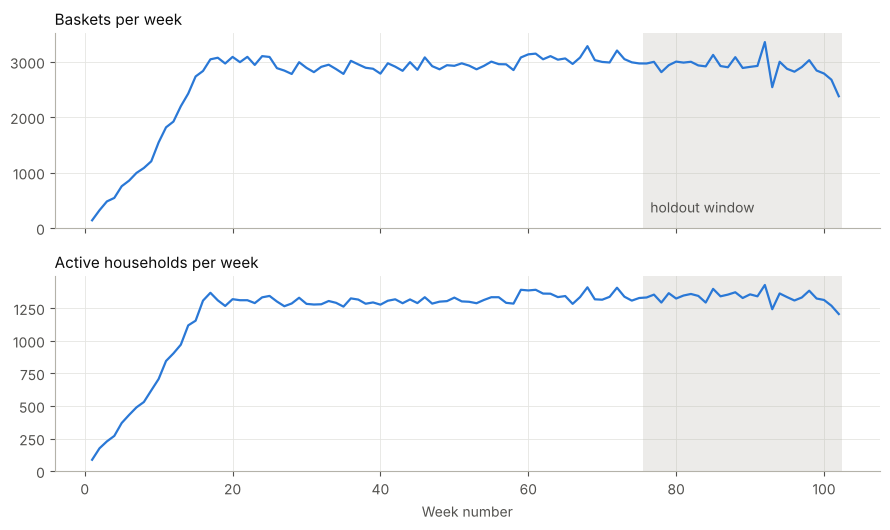

Panel ramp-up: active households reach 95% of their steady level (~1302) only in week 16. Weeks 1-15 describe a partially recruited panel, so category incidence and promo shares in those weeks are noisier. Keep them in estimation but include week effects, and report a check that drops them.


In [6]:
wk = tx.groupby("week_no").agg(baskets=("basket_id", "nunique"), households=("household_key", "nunique"), spend=("sales_value", "sum"))
fig, axes = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True)
for ax, col, title in zip(axes, ["baskets", "households"], ["Baskets per week", "Active households per week"]):
    ax.plot(wk.index, wk[col], color=C[0])
    ax.axvspan(CFG["EST_END"] + 0.5, CFG["N_WEEKS"] + 0.5, color=GREY, alpha=0.25, lw=0)
    ax.set_title(title); ax.set_ylim(0)
axes[0].text(CFG["EST_END"] + 1.5, axes[0].get_ylim()[1] * 0.08, "holdout window", color=INK2)
axes[1].set_xlabel("Week number")
save(fig, "01_weekly_activity")
ref = wk.households.iloc[20:60].median()
stable = int(wk.households[wk.households >= 0.95 * ref].index.min())
KEY["stable_week"] = stable
print(f"Panel ramp-up: active households reach 95% of their steady level (~{ref:.0f}) only in week {stable}. "
      f"Weeks 1-{stable - 1} describe a partially recruited panel, so category incidence and promo shares in those weeks "
      "are noisier. Keep them in estimation but include week effects, and report a check that drops them.")

### 3.3 Household tenure and trip counts

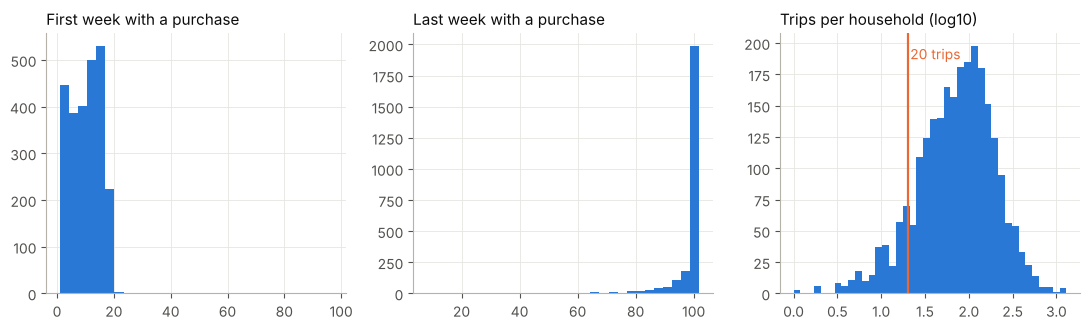

,min trips,households,share
0,5,2477,0.991
1,10,2402,0.961
2,20,2233,0.893
3,40,1858,0.743
4,80,1235,0.494


100% of households make their first purchase by week 20, and 88% are still buying in weeks 95-102, so households are long-lived.
Median shopping span: 90 weeks. Households shop in only 55% of weeks inside their span, so the outside option must be defined on shopping weeks, not calendar weeks (Part 8).


In [7]:
hh = tx.groupby("household_key").agg(first_week=("week_no", "min"), last_week=("week_no", "max"),
                                     shop_weeks=("week_no", "nunique"), trips=("basket_id", "nunique"),
                                     spend=("sales_value", "sum"))
hh["span"] = hh.last_week - hh.first_week + 1
hh["fill"] = hh.shop_weeks / hh.span

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].hist(hh.first_week, bins=30, color=C[0]); axes[0].set_title("First week with a purchase")
axes[1].hist(hh.last_week, bins=30, color=C[0]); axes[1].set_title("Last week with a purchase")
axes[2].hist(np.log10(hh.trips), bins=40, color=C[0]); axes[2].set_title("Trips per household (log10)")
axes[2].axvline(np.log10(CFG["MIN_TRIPS_SEG"]), color=C[1]); axes[2].text(np.log10(CFG["MIN_TRIPS_SEG"]) + 0.03, axes[2].get_ylim()[1] * 0.9, "20 trips", color=C[1])
save(fig, "02_household_tenure")

thr = pd.DataFrame({"min trips": [5, 10, 20, 40, 80]})
thr["households"] = [(hh.trips >= t).sum() for t in thr["min trips"]]
thr["share"] = (thr.households / len(hh)).round(3)
display(thr)
print(f"{(hh.first_week <= 20).mean():.0%} of households make their first purchase by week 20, and {(hh.last_week >= 95).mean():.0%} are still buying in weeks 95-102, so households are long-lived.")
print(f"Median shopping span: {hh.span.median():.0f} weeks. Households shop in only {hh.fill.median():.0%} of weeks inside their span, "
      f"so the outside option must be defined on shopping weeks, not calendar weeks (Part 8).")
KEY["hh_ge20_trips"] = int((hh.trips >= CFG["MIN_TRIPS_SEG"]).sum())

### 3.4 Stores: the store-level analysis only has data for a minority of stores

Store-level mixes and assortments need enough households per store. The distribution is extremely skewed.

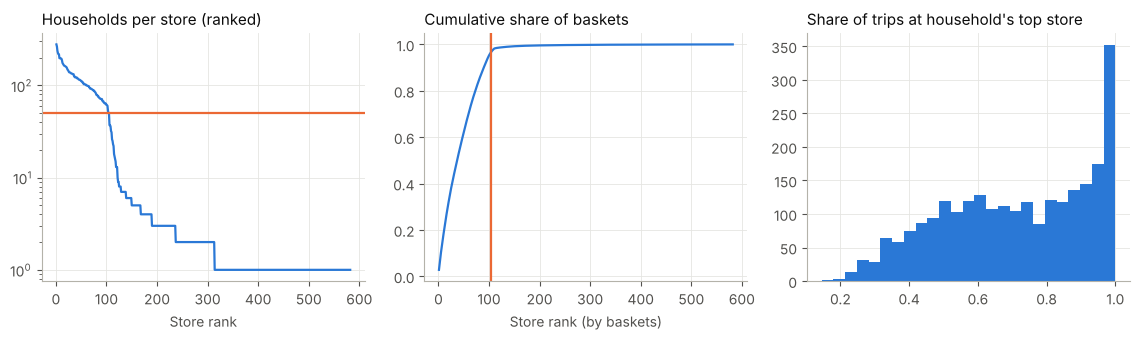

,min households,stores,share of baskets
0,10,122,0.986
1,30,110,0.977
2,50,104,0.945
3,100,61,0.665


Median store has 2 households. 104 stores have >= 50 households and they carry 94% of baskets.
41% of households do >= 80% of their trips at one store, the median household shops at 5 different stores.


In [8]:
st = tx.groupby("store_id").agg(households=("household_key", "nunique"), baskets=("basket_id", "nunique"),
                                spend=("sales_value", "sum")).sort_values("baskets", ascending=False)
st["cum_baskets"] = st.baskets.cumsum() / st.baskets.sum()
st["eligible"] = st.households >= CFG["STORE_MIN_HH"]

hs = tx.groupby(["household_key", "store_id"]).basket_id.nunique().rename("trips").reset_index()
hs["share"] = hs.trips / hs.groupby("household_key").trips.transform("sum")
home = hs.sort_values(["household_key", "share"], ascending=[True, False]).drop_duplicates("household_key").set_index("household_key")
hh["home_store"], hh["home_share"] = home.store_id, home.share

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))
axes[0].plot(range(1, len(st) + 1), st.households.sort_values(ascending=False).values, color=C[0])
axes[0].axhline(CFG["STORE_MIN_HH"], color=C[1]); axes[0].set_yscale("log")
axes[0].set_title("Households per store (ranked)"); axes[0].set_xlabel("Store rank")
axes[1].plot(range(1, len(st) + 1), st.cum_baskets.values, color=C[0])
n_el = int(st.eligible.sum())
axes[1].axvline(n_el, color=C[1]); axes[1].set_title("Cumulative share of baskets"); axes[1].set_xlabel("Store rank (by baskets)")
axes[2].hist(hh.home_share, bins=25, color=C[0]); axes[2].set_title("Share of trips at household's top store")
save(fig, "03_stores")

tbl = pd.DataFrame({"min households": [10, 30, 50, 100]})
tbl["stores"] = [(st.households >= t).sum() for t in tbl["min households"]]
tbl["share of baskets"] = [round(st.loc[st.households >= t, "baskets"].sum() / st.baskets.sum(), 3) for t in tbl["min households"]]
display(tbl)
print(f"Median store has {st.households.median():.0f} households. {n_el} stores have >= {CFG['STORE_MIN_HH']} households "
      f"and they carry {st.loc[st.eligible, 'baskets'].sum() / st.baskets.sum():.0%} of baskets.")
print(f"{(hh.home_share >= 0.8).mean():.0%} of households do >= 80% of their trips at one store, the median household shops at "
      f"{hs.groupby('household_key').size().median():.0f} different stores.")
KEY.update(stores_ge50=n_el, basket_share_ge50=float(st.loc[st.eligible, "baskets"].sum() / st.baskets.sum()),
           median_hh_per_store=float(st.households.median()))

### 3.5 Demographics: coverage and selection bias

Only a minority of households have demographics. The question that matters for the thesis is whether those households behave differently, because demographic segmentation can then only be used as a comparison on a self-selected subset.

Households with demographics: 801 of 2500 (32.0%)


,metric,median_with_demo,median_without_demo,mann_whitney_p
0,trips,139.00,52.00,0.0
1,shop_weeks,73.00,36.00,0.0
2,spend,4676.43,1396.93,0.0


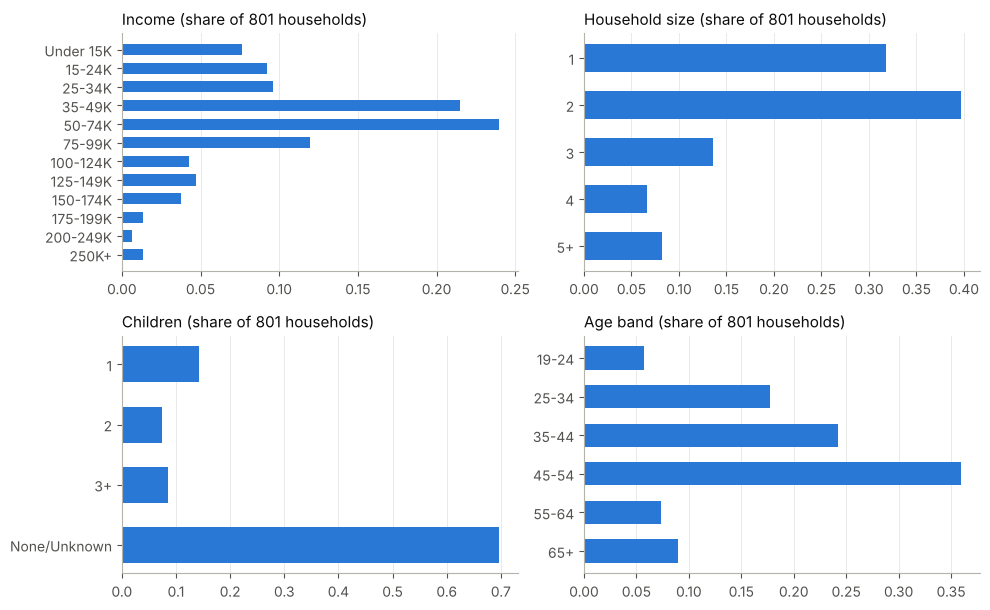

Missing or unknown demographic values: 0
Households with demographics make 2.7x as many trips (median) as those without: demographic samples are heavy, loyal shoppers.


In [9]:
hh["has_demo"] = hh.index.isin(demo.household_key)
print(f"Households with demographics: {hh.has_demo.sum()} of {len(hh)} ({hh.has_demo.mean():.1%})")
cmp_rows = []
for col in ["trips", "shop_weeks", "spend"]:
    a, b = hh.loc[hh.has_demo, col], hh.loc[~hh.has_demo, col]
    p = mannwhitneyu(a, b).pvalue
    cmp_rows.append(dict(metric=col, median_with_demo=a.median(), median_without_demo=b.median(), mann_whitney_p=p))
display(pd.DataFrame(cmp_rows).round(4))

def income_key(s):
    s = str(s)
    if s.lower().startswith("under"): return 0
    return int(re.search(r"\d+", s).group())
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
for ax, (col, title) in zip(axes.ravel(), [("income_desc", "Income"), ("household_size_desc", "Household size"),
                                           ("kid_category_desc", "Children"), ("age_desc", "Age band")]):
    vc = demo[col].value_counts(normalize=True)
    order = sorted(vc.index, key=income_key) if col == "income_desc" else sorted(vc.index, key=lambda s: str(s))
    ax.barh(range(len(order)), vc.loc[order].values, color=C[0], height=0.6)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
    ax.set_title(f"{title} (share of {len(demo)} households)"); ax.grid(axis="y", visible=False)
save(fig, "04_demographics")
print("Missing or unknown demographic values:", int(demo.isna().sum().sum()))
KEY["hh_with_demo"] = int(hh.has_demo.sum())
KEY["demo_trips_ratio"] = float(hh.loc[hh.has_demo, "trips"].median() / hh.loc[~hh.has_demo, "trips"].median())
print(f"Households with demographics make {KEY['demo_trips_ratio']:.1f}x as many trips (median) as those without: demographic samples are heavy, loyal shoppers.")

## 4. Category screening: why cereal and soup

A category is usable for this project if it has (a) many households with enough purchases to estimate segment-level choice models, (b) a manageable but non-trivial number of SKUs, and (c) a match in the Dominick's data for the external robustness check. The Dominick's codes below were taken from the Kilts Center download page. Dominick's has no yogurt or pasta category.

,lines,skus,revenue,households,hh_10plus,dominicks,role
commodity_desc,,,,,,,
SOFT DRINKS,117209,1696,327645.0,2405,1854,SDR,
FLUID MILK PRODUCTS,85494,455,205356.0,2421,1796,none,
BAKED BREAD/BUNS/ROLLS,83117,1169,145931.0,2400,1787,none,
CHEESE,74783,1096,189528.0,2350,1640,CHE,
BAG SNACKS,66677,1521,148375.0,2347,1562,none,
BEEF,48635,1108,312103.0,2238,1327,none,
SOUP,46097,976,87800.0,2195,1265,CSO,main
FRZN MEAT/MEAT DINNERS,55976,1268,160517.0,2069,1238,none,
VEGETABLES - SHELF STABLE,41585,831,57690.0,2138,1162,none,


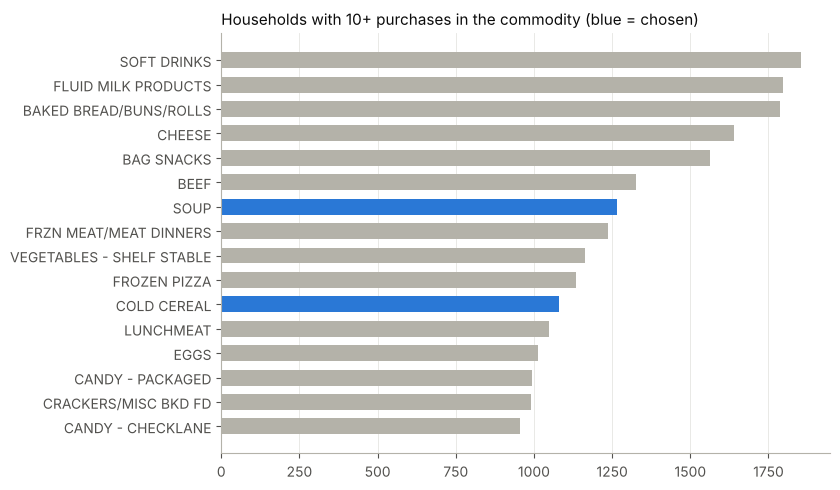

Cereal and soup combine strong household depth with a Dominick's match. Yogurt has depth but no Dominick's counterpart.
Soft drinks and cheese have more data but too many SKUs and flavours to model in 12 weeks.


In [10]:
DOMINICKS = {"COLD CEREAL": "CER", "SOUP": "CSO", "CRACKERS/MISC BKD FD": "CRA", "REFRGRATD JUICES/DRNKS": "RFJ",
             "CHEESE": "CHE", "SOFT DRINKS": "SDR", "COOKIES": "COO", "BATH TISSUES": "TTI", "PAPER TOWELS": "PTW",
             "LAUNDRY DETERGENTS": "LND", "BEERS/ALES": "BER", "DISHWASH DETERGENTS": "DID"}
CHOSEN = ["COLD CEREAL", "SOUP"]

cl = tx[tx.sales_value > 0]
screen = cl.groupby("commodity_desc").agg(lines=("basket_id", "size"), skus=("product_id", "nunique"),
                                          revenue=("sales_value", "sum"), households=("household_key", "nunique"))
screen["hh_10plus"] = cl.groupby(["commodity_desc", "household_key"]).size().ge(10).groupby("commodity_desc").sum()
screen["dominicks"] = screen.index.map(DOMINICKS).fillna("none")
screen["role"] = np.where(screen.index.isin(CHOSEN), "main", np.where(screen.index == "YOGURT", "Dunnhumby-only extra", ""))
top = screen.sort_values("hh_10plus", ascending=False).head(16)
display(top.assign(revenue=top.revenue.round(0)))

fig, ax = plt.subplots(figsize=(8.5, 5))
colors = [C[0] if i in CHOSEN else GREY for i in top.index[::-1]]
ax.barh(top.index[::-1], top.hh_10plus[::-1], color=colors, height=0.65)
ax.set_title("Households with 10+ purchases in the commodity (blue = chosen)"); ax.grid(axis="y", visible=False)
save(fig, "05_category_screening")
print("Cereal and soup combine strong household depth with a Dominick's match. Yogurt has depth but no Dominick's counterpart.")
print("Soft drinks and cheese have more data but too many SKUs and flavours to model in 12 weeks.")

## 5. Category definition, SKU attributes, concentration and lifecycle

### 5.1 What counts as cereal and soup

- **Cereal:** `COLD CEREAL`, minus a handful of candy and seasonal items mis-filed in the commodity.
- **Soup:** `SOUP` contains very different products. Ramen, dry soup, bouillon and broth are not substitutes for canned or ready-to-serve soup, so the soup definition keeps the canned/ready-to-serve/microwavable sub-commodities (closest to Dominick's *Canned Soup*). This choice is a sensitivity item, so it is stored in one place.

In [11]:
SOUP_KEEP = {"RTS SOUP: CHUNKY/HOMESTYLE ET", "CONDENSED SOUP", "CANS SOUP/CHILI", "MICROWAVABLE SOUPS", "CUPS", "ASCEPTIC"}
CATS = ["cereal", "soup"]

def in_scope(name, df):
    if name == "cereal":
        return (df.commodity_desc == "COLD CEREAL") & ~df.sub_commodity_desc.str.contains("CANDY|SEASONAL")
    if name == "soup":
        return (df.commodity_desc == "SOUP") & df.sub_commodity_desc.isin(SOUP_KEEP)

sub = (cl[cl.commodity_desc.isin(CHOSEN)].groupby(["commodity_desc", "sub_commodity_desc"])
       .agg(skus=("product_id", "nunique"), revenue=("sales_value", "sum")).reset_index())
sub["in_scope"] = [bool(in_scope("cereal" if c == "COLD CEREAL" else "soup", pd.DataFrame({"commodity_desc": [c], "sub_commodity_desc": [s]})).iloc[0])
                   for c, s in zip(sub.commodity_desc, sub.sub_commodity_desc)]
sub["revenue"] = sub.revenue.round(0)
display(sub.sort_values(["commodity_desc", "revenue"], ascending=[True, False]))
for c in CHOSEN:
    s = sub[sub.commodity_desc == c]
    print(f"{c}: in-scope share of revenue = {s.loc[s.in_scope, 'revenue'].sum() / s.revenue.sum():.1%}")

,commodity_desc,sub_commodity_desc,skus,revenue,in_scope
3,COLD CEREAL,KIDS CEREAL,268,46334.0,True
1,COLD CEREAL,ALL FAMILY CEREAL,181,36703.0,True
0,COLD CEREAL,ADULT CEREAL,181,28504.0,True
4,COLD CEREAL,MISC. CEREAL,4,156.0,True
6,COLD CEREAL,SEASONAL MISCELLANEOUS,1,3.0,False
5,COLD CEREAL,SEASONAL CANDY BAGS-CHOCOLATE,2,2.0,False
2,COLD CEREAL,CANDY BAGS-CHOCOCLATE,1,1.0,False
13,SOUP,CONDENSED SOUP,247,33514.0,True
21,SOUP,RTS SOUP: CHUNKY/HOMESTYLE ET,290,30683.0,True
10,SOUP,BROTH,67,6713.0,False


COLD CEREAL: in-scope share of revenue = 100.0%
SOUP: in-scope share of revenue = 77.7%


### 5.2 SKU attributes

In [12]:
def parse_size(s):
    """Ounces from strings like '14 OZ', '10 3/4 OZ', '12.2 OZ', '1 LB'. NaN for counts/packs such as '6 PK/3 OZ'."""
    if pd.isna(s): return np.nan
    s = str(s).strip().upper()
    m = re.match(r"^(\d+)\s+(\d+)/(\d+)\s*(OZ|O|OUNCE)?", s)
    if m: return int(m.group(1)) + int(m.group(2)) / int(m.group(3))
    m = re.match(r"^(\d*\.?\d+)\s*(OZ|OUNCE|O)\b", s)
    if m: return float(m.group(1))
    m = re.match(r"^(\d*\.?\d+)\s*LB\b", s)
    if m: return float(m.group(1)) * 16
    return np.nan

cat_lines, sku_master = {}, {}
for name in CATS:
    m = products[in_scope(name, products)].copy()
    L = tx[tx.product_id.isin(m.product_id)].copy()
    L["split"] = np.where(L.week_no <= CFG["EST_END"], "est", "holdout")
    m["is_private"] = m.brand.eq("Private")
    m["size_oz_raw"] = m.curr_size_of_product.map(parse_size)
    m["size_imputed"] = m.size_oz_raw.isna()
    m["size_oz"] = m.size_oz_raw.fillna(m.groupby("sub_commodity_desc").size_oz_raw.transform("median")).fillna(m.size_oz_raw.median())
    m["multipack"] = m.curr_size_of_product.fillna("").str.contains(r"\bPK\b|\bCT\b|/", regex=True)

    # manufacturer group: private label, then the manufacturers that make up ~92% of revenue (max 6), rest = OTHER
    rev_m = L[~L.brand.eq("Private")].groupby("manufacturer").sales_value.sum().sort_values(ascending=False)
    keep = []
    for mf, share in (rev_m / rev_m.sum()).cumsum().items():
        keep.append(mf)
        if share >= 0.92 or len(keep) == 6: break
    m["mf_group"] = np.where(m.is_private, "PRIVATE", np.where(m.manufacturer.isin(keep), "M" + m.manufacturer.astype(str), "OTHER"))
    rev_s = L.groupby("sub_commodity_desc").sales_value.sum(); rev_s = rev_s / rev_s.sum()
    m["sub_group"] = np.where(m.sub_commodity_desc.map(rev_s).fillna(0) >= 0.03, m.sub_commodity_desc, "OTHER")
    m["size_bucket"] = pd.qcut(m.size_oz, 3, labels=["small", "medium", "large"], duplicates="drop").astype(str)
    cat_lines[name], sku_master[name] = L, m.set_index("product_id")
    print(f"{name}: {len(m)} SKUs in scope, {len(L):,} purchase lines, {L.household_key.nunique():,} households | "
          f"size parsed for {(~m.size_imputed).mean():.0%} of SKUs | mf groups: {sorted(m.mf_group.unique())}")

# The private-label flag and the "manufacturer 69" id should coincide. Check, because mf_group relies on the flag.
for name in CATS:
    m = sku_master[name]
    print(name, "private-label SKUs by manufacturer id:", m[m.is_private].manufacturer.value_counts().head(3).to_dict())

cereal: 634 SKUs in scope, 37,794 purchase lines, 2,140 households | size parsed for 99% of SKUs | mf groups: ['M1046', 'M194', 'M584', 'M794', 'OTHER', 'PRIVATE']


soup: 679 SKUs in scope, 31,693 purchase lines, 2,019 households | size parsed for 99% of SKUs | mf groups: ['M1251', 'M890', 'OTHER', 'PRIVATE']
cereal private-label SKUs by manufacturer id: {69: 153}
soup private-label SKUs by manufacturer id: {69: 101}


### 5.3 Concentration, sparsity and the "core SKU" threshold

Most SKUs are bought by very few households. A SKU-level choice model cannot give each such SKU its own parameters, so SKUs are split into **core alternatives** (stand-alone, enough purchase lines in the estimation window) and a **tail** that is pooled by manufacturer group and sub-commodity. The threshold uses the estimation window only, so it never looks at the holdout.

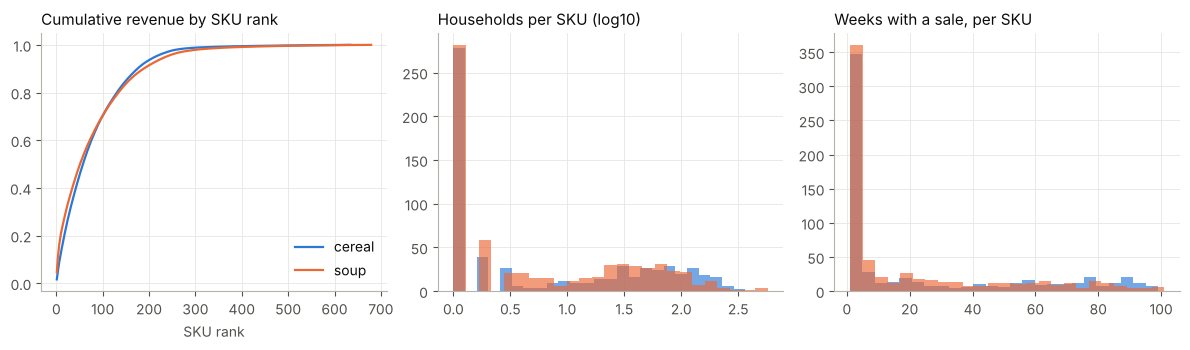

core_skus        share_of_est_lines       
category         cereal   soup             cereal   soup
min_est_lines                                           
10                245.0  228.0              0.979  0.964
20                225.0  200.0              0.969  0.944
30                207.0  167.0              0.953  0.904
50                169.0  122.0              0.899  0.818
100               101.0   54.0              0.716  0.570

cereal: 634 SKUs sold. 349 (55%) bought by fewer than 5 households; 131 SKUs make 80% of revenue.
soup: 679 SKUs sold. 381 (56%) bought by fewer than 5 households; 134 SKUs make 80% of revenue.


In [13]:
sku_stats = {}
for name in CATS:
    L = cat_lines[name]; L = L[L.sales_value > 0]
    s = L.groupby("product_id").agg(lines=("basket_id", "size"), households=("household_key", "nunique"),
                                   revenue=("sales_value", "sum"), first_week=("week_no", "min"), last_week=("week_no", "max"),
                                   weeks_sold=("week_no", "nunique"))
    est = L[L.split == "est"].groupby("product_id").agg(est_lines=("basket_id", "size"), est_hh=("household_key", "nunique"))
    s = s.join(est).fillna({"est_lines": 0, "est_hh": 0}).sort_values("revenue", ascending=False)
    s["cum_rev"] = s.revenue.cumsum() / s.revenue.sum()
    sku_stats[name] = s

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for name, col in zip(CATS, C):
    s = sku_stats[name]
    axes[0].plot(range(1, len(s) + 1), s.cum_rev.values, color=col, label=name)
    axes[1].hist(np.log10(s.households), bins=25, alpha=0.65, color=col, label=name)
    axes[2].hist(s.weeks_sold, bins=25, alpha=0.65, color=col, label=name)
axes[0].set_title("Cumulative revenue by SKU rank"); axes[0].set_xlabel("SKU rank"); axes[0].legend()
axes[1].set_title("Households per SKU (log10)"); axes[2].set_title("Weeks with a sale, per SKU")
save(fig, "06_sku_concentration")

rows = []
for th in [10, 20, 30, 50, 100]:
    for name in CATS:
        s = sku_stats[name]; core = s[s.est_lines >= th]
        rows.append(dict(category=name, min_est_lines=th, core_skus=len(core), share_of_est_lines=round(core.est_lines.sum() / s.est_lines.sum(), 3)))
thr_tbl = pd.DataFrame(rows)
display(thr_tbl.pivot(index="min_est_lines", columns="category", values=["core_skus", "share_of_est_lines"]))
for name in CATS:
    s = sku_stats[name]
    print(f"{name}: {len(s)} SKUs sold. {(s.households < 5).sum()} ({(s.households < 5).mean():.0%}) bought by fewer than 5 households; "
          f"{(s.cum_rev <= 0.8).sum() + 1} SKUs make 80% of revenue.")
    KEY[f"{name}_skus"] = len(s); KEY[f"{name}_lt5hh"] = int((s.households < 5).sum()); KEY[f"{name}_skus80"] = int((s.cum_rev <= 0.8).sum() + 1)

In [14]:
for name in CATS:
    m, s = sku_master[name], sku_stats[name]
    m["est_lines"] = s.est_lines.reindex(m.index).fillna(0).astype(int)
    m["est_households"] = s.est_hh.reindex(m.index).fillna(0).astype(int)
    m["total_lines"] = s.lines.reindex(m.index).fillna(0).astype(int)
    m["first_week"], m["last_week"] = s.first_week.reindex(m.index), s.last_week.reindex(m.index)
    m["core"] = m.est_lines >= CFG["CORE_MIN_LINES"]
    m["alt_id"] = np.where(m.core, m.index.astype(str), "TAIL|" + m.mf_group + "|" + m.sub_group)
    m["new_in_holdout"] = (m.est_lines == 0) & (m.total_lines > 0)
    n_alt = m.loc[m.total_lines > 0, "alt_id"].nunique()
    print(f"{name}: core SKUs = {int(m.core.sum())}, tail groups = {m.loc[~m.core & (m.total_lines > 0), 'alt_id'].nunique()}, "
          f"alternatives in the choice model = {n_alt}, SKUs first sold in holdout = {int(m.new_in_holdout.sum())}")
    KEY[f"{name}_core"], KEY[f"{name}_alts"] = int(m.core.sum()), int(n_alt)

cereal: core SKUs = 207, tail groups = 20, alternatives in the choice model = 227, SKUs first sold in holdout = 76
soup: core SKUs = 167, tail groups = 11, alternatives in the choice model = 178, SKUs first sold in holdout = 106


## 6. Price, promotion and display/mailer

### 6.1 Are prices store-specific?

The choice model needs a price for every available alternative. Purchases give a price only for items that were bought, so a chain-wide weekly shelf price is only usable if prices barely differ across stores.

In [15]:
rows = []
for name in CATS:
    L = cat_lines[name]; L = L[L.shelf_price.notna() & (L.sales_value > 0)]
    g = L.groupby(["product_id", "week_no"]).agg(n=("shelf_price", "size"), stores=("store_id", "nunique"),
                                               med=("shelf_price", "median"), sd=("shelf_price", "std"),
                                               lo=("shelf_price", "min"), hi=("shelf_price", "max"))
    g = g[(g.n >= 3) & (g.stores >= 2)]
    rows.append(dict(category=name, sku_weeks_compared=len(g), median_CV=round((g.sd / g.med).median(), 4),
                     share_with_range_over_10pct=round(((g.hi - g.lo) / g.med > 0.10).mean(), 3)))
price_consistency = pd.DataFrame(rows); display(price_consistency)
KEY["price_range10"] = {r["category"]: r["share_with_range_over_10pct"] for r in rows}
print("Shelf prices are almost identical across stores within a SKU-week, so a chain-wide weekly shelf price is a reasonable "
      "price for non-purchased alternatives. Store-level price differences are small and are noted as a limitation.")

,category,sku_weeks_compared,median_CV,share_with_range_over_10pct
0,cereal,5022,0.0,0.070
1,soup,3524,0.0,0.038


Shelf prices are almost identical across stores within a SKU-week, so a chain-wide weekly shelf price is a reasonable price for non-purchased alternatives. Store-level price differences are small and are noted as a limitation.


### 6.2 Price levels, promotion frequency and depth

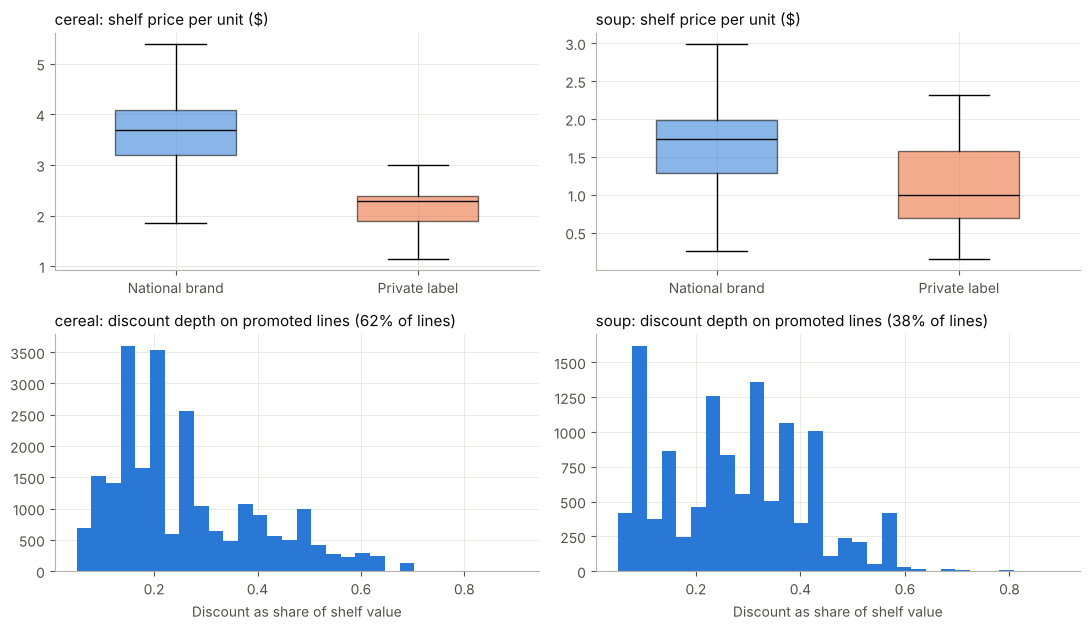

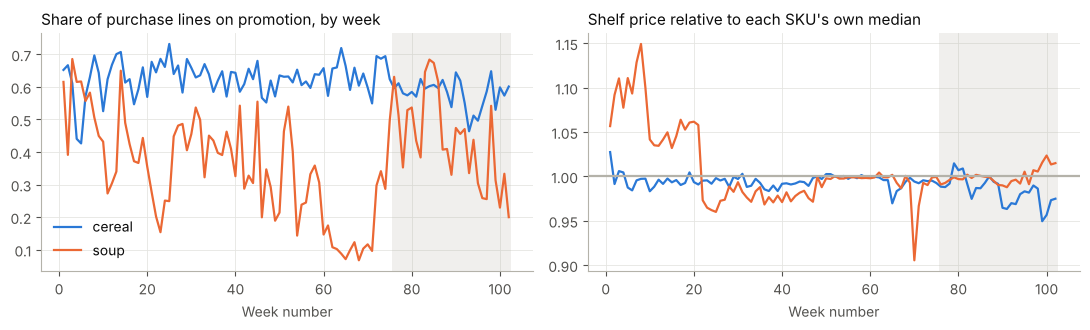

cereal: 61.8% of purchase lines are on promotion (discount >= 5%); mean paid-vs-shelf discount 16.1%
soup: 37.9% of purchase lines are on promotion (discount >= 5%); mean paid-vs-shelf discount 10.5%


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
for j, name in enumerate(CATS):
    L = cat_lines[name]; L = L[L.shelf_price.notna() & (L.sales_value > 0)]
    data = [L.loc[~L.brand.eq("Private"), "shelf_price"], L.loc[L.brand.eq("Private"), "shelf_price"]]
    bp = axes[0, j].boxplot(data, showfliers=False, widths=0.5, patch_artist=True)
    axes[0, j].set_xticklabels(["National brand", "Private label"])
    for patch, col in zip(bp["boxes"], [C[0], C[1]]): patch.set_facecolor(col); patch.set_alpha(0.55)
    for med in bp["medians"]: med.set_color(INK)
    axes[0, j].set_title(f"{name}: shelf price per unit ($)")
    pr = L[L.promo]
    axes[1, j].hist(pr.disc_share, bins=30, color=C[0])
    axes[1, j].set_title(f"{name}: discount depth on promoted lines ({len(pr) / len(L):.0%} of lines)")
    axes[1, j].set_xlabel("Discount as share of shelf value")
save(fig, "07_price_promo")

wk_rows = []
for name in CATS:
    L = cat_lines[name]; L = L[L.shelf_price.notna() & (L.sales_value > 0)].copy()
    L["rel_price"] = L.shelf_price / L.groupby("product_id").shelf_price.transform("median")
    w = L.groupby("week_no").agg(promo_incidence=("promo", "mean"), rel_price=("rel_price", "mean"))
    w["category"] = name; wk_rows.append(w.reset_index())
wkp = pd.concat(wk_rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for name, col in zip(CATS, C):
    d = wkp[wkp.category == name]
    axes[0].plot(d.week_no, d.promo_incidence, color=col, label=name); axes[1].plot(d.week_no, d.rel_price, color=col, label=name)
axes[0].set_title("Share of purchase lines on promotion, by week"); axes[0].legend()
axes[1].set_title("Shelf price relative to each SKU's own median"); axes[1].axhline(1, color=GREY)
for ax in axes: ax.set_xlabel("Week number"); ax.axvspan(CFG["EST_END"] + 0.5, CFG["N_WEEKS"] + 0.5, color=GREY, alpha=0.2, lw=0)
save(fig, "08_promo_over_time")
for name in CATS:
    L = cat_lines[name]; L = L[L.sales_value > 0]
    print(f"{name}: {L.promo.mean():.1%} of purchase lines are on promotion (discount >= {CFG['PROMO_THRESH']:.0%}); "
          f"mean paid-vs-shelf discount {L.disc_share.mean():.1%}")
    KEY[f"{name}_promo"] = float(L.promo.mean())

### 6.3 Display and mailer flags from `causal_data.csv`

`causal_data.csv` is 695 MB, so it is read in chunks and filtered to the modelled SKUs. It lists display and mailer placement by product, store and week. Earlier checks showed it covers only part of the promotional activity, so the discount-based promo flag stays the primary promotion measure. Display and mailer are secondary controls.

In [17]:
ids = set().union(*[set(sku_master[n].index) for n in CATS])
parts = []
for ch in pd.read_csv(RAW_DIR / "causal_data.csv", chunksize=2_000_000, dtype={"display": str, "mailer": str}):
    ch.columns = [c.lower() for c in ch.columns]
    parts.append(ch[ch.product_id.isin(ids)])
causal = pd.concat(parts, ignore_index=True)
causal["display_on"] = causal.display.fillna("0").ne("0")
causal["mailer_on"] = causal.mailer.fillna("0").ne("0")
print(f"causal rows for modelled SKUs: {len(causal):,} | weeks {causal.week_no.min()}-{causal.week_no.max()} | duplicate keys: {causal.duplicated(['product_id','store_id','week_no']).sum()}")
print("display codes:", causal.display.value_counts().head(8).to_dict())
print("mailer codes :", causal.mailer.value_counts().head(8).to_dict())

kcols = ["product_id", "store_id", "week_no"]
for name in CATS:
    L = cat_lines[name].merge(causal[kcols + ["display_on", "mailer_on"]], on=kcols, how="left")
    L["in_causal"] = L.display_on.notna()
    L[["display_on", "mailer_on"]] = L[["display_on", "mailer_on"]].fillna(False).astype(bool)
    cat_lines[name] = L

rows = []
for name in CATS:
    L = cat_lines[name]; L = L[L.sales_value > 0]
    state = np.select([~L.in_causal, L.display_on & L.mailer_on, L.display_on, L.mailer_on], ["not in causal_data", "display + mailer", "display only", "mailer only"], "in causal_data, no display/mailer")
    t = pd.crosstab(state, L.promo, normalize="index").round(3)
    t.columns = ["share not promo", "share promo"]
    t["lines"] = pd.Series(state).value_counts()
    t.index.name = "causal state"
    t.insert(0, "category", name); rows.append(t.reset_index())
display(pd.concat(rows, ignore_index=True))
for name in CATS:
    L = cat_lines[name]; L = L[L.sales_value > 0]
    KEY[f"{name}_in_causal"] = float(L.in_causal.mean()); KEY[f"{name}_promo_in_causal"] = float(L.loc[L.promo, "in_causal"].mean())
    print(f"{name}: {L.in_causal.mean():.0%} of purchase lines appear in causal_data; of promoted lines only {L.loc[L.promo, 'in_causal'].mean():.0%} do.")

causal rows for modelled SKUs: 732,131 | weeks 9-101 | duplicate keys: 0
display codes: {'0': 407671, '5': 145191, '3': 57377, 'A': 42773, '9': 22353, '7': 14971, '4': 14361, '2': 12557}
mailer codes : {'A': 429047, '0': 171474, 'D': 86165, 'H': 27586, 'J': 13120, 'F': 4631, 'X': 108}


,causal state,category,share not promo,share promo,lines
0,display + mailer,cereal,0.002,0.998,3845
1,display only,cereal,0.193,0.807,1944
2,mailer only,cereal,0.009,0.991,3235
3,not in causal_data,cereal,0.488,0.512,28769
4,display + mailer,soup,0.057,0.943,1279
5,display only,soup,0.287,0.713,1549
6,mailer only,soup,0.070,0.930,1762
7,not in causal_data,soup,0.703,0.297,27103


cereal: 24% of purchase lines appear in causal_data; of promoted lines only 37% do.
soup: 14% of purchase lines appear in causal_data; of promoted lines only 33% do.


## 7. SKU-week availability and price panel

Dunnhumby does not record what was on the shelf. Availability is therefore inferred:

- A SKU is *in its life* between its first and last chain-wide sale.
- Inside its life, a run of `GAP_WEEKS` (8) or more weeks with no chain-wide sale marks the SKU as unavailable (seasonal gap or temporary delisting).
- Availability is defined **chain-wide**. At store level a SKU sells in a median of only ~2 of 102 weeks even in the largest stores, so store-level availability cannot be observed. The store-level analysis therefore changes the *demand weights* by store, while the candidate assortment is the chain's available range. This is a limitation to state in the thesis.
- Missing weekly prices are forward/back-filled for at most 4 weeks, then set to the SKU's median shelf price, and flagged.

In [18]:
def build_sku_week(name):
    L = cat_lines[name]; L = L[(L.sales_value > 0) & L.shelf_price.notna()]
    obs = L.groupby(["product_id", "week_no"]).agg(
        units=("quantity", "sum"), lines=("basket_id", "size"), households=("household_key", "nunique"),
        shelf_price=("shelf_price", "median"), paid_price=("paid_price", "median"),
        promo_share=("promo", "mean"), disc_depth=("disc_share", "mean"),
        display_share=("display_on", "mean"), mailer_share=("mailer_on", "mean")).reset_index()
    life = obs.groupby("product_id").week_no.agg(["min", "max"])
    grid = pd.DataFrame([(pid, w) for pid, r in life.iterrows() for w in range(int(r["min"]), int(r["max"]) + 1)],
                        columns=["product_id", "week_no"])
    g = grid.merge(obs, on=["product_id", "week_no"], how="left").sort_values(["product_id", "week_no"]).reset_index(drop=True)
    g["sold"] = g.lines.fillna(0) > 0
    run_id = (g.sold != g.groupby("product_id").sold.shift()).cumsum()
    g["zero_run_len"] = np.where(g.sold, 0, g.groupby(run_id).week_no.transform("size"))
    g["available"] = ~((~g.sold) & (g.zero_run_len >= CFG["GAP_WEEKS"]))
    lim = CFG["PRICE_FILL_LIMIT"]
    g["price_observed"] = g.shelf_price.notna()
    g["shelf_price_filled"] = g.groupby("product_id").shelf_price.transform(lambda s: s.ffill(limit=lim).bfill(limit=lim))
    g["shelf_price_filled"] = g.shelf_price_filled.fillna(g.groupby("product_id").shelf_price.transform("median"))
    g[["units", "lines", "households"]] = g[["units", "lines", "households"]].fillna(0)
    m = sku_master[name]
    g["core"] = g.product_id.map(m.core); g["alt_id"] = g.product_id.map(m.alt_id)
    g["split"] = np.where(g.week_no <= CFG["EST_END"], "est", "holdout")
    return g

sku_week = {n: build_sku_week(n) for n in CATS}
for n in CATS:
    g = sku_week[n]
    print(f"{n}: {len(g):,} SKU-week cells | available {g.available.mean():.1%} | price observed {g.price_observed.mean():.1%} | "
          f"zero-run cells marked unavailable {(~g.available).sum():,}")
    KEY[f"{n}_avail_cells"] = len(g)

cereal: 24,565 SKU-week cells | available 84.0% | price observed 60.5% | zero-run cells marked unavailable 3,928
soup: 27,785 SKU-week cells | available 76.6% | price observed 48.3% | zero-run cells marked unavailable 6,511


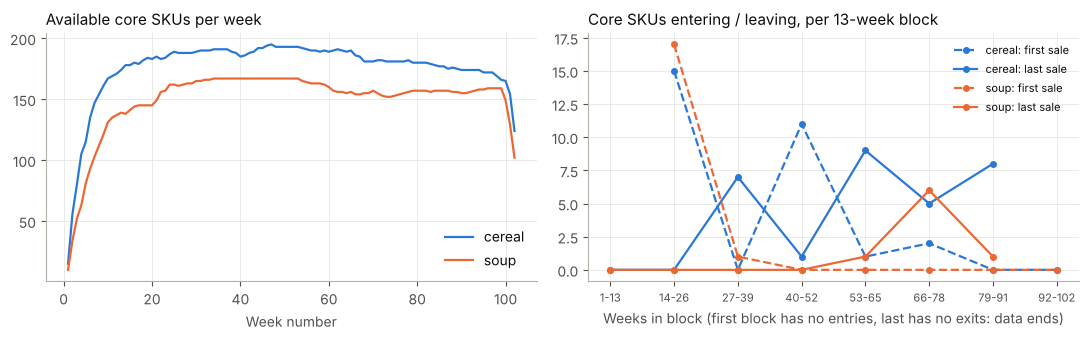

Core SKUs enter and leave steadily. The first block cannot show entries and the last cannot show exits, because the data starts and ends there (censoring). Many entries in weeks 14-26 are panel recruitment finishing, not product launches. Exits (solid lines) are the genuine delisting signal that RQ2 relies on.


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
BLK = 13
for name, col in zip(CATS, C):
    g = sku_week[name]
    a = g[g.available & g.core].groupby("week_no").size().reindex(range(1, CFG["N_WEEKS"] + 1))
    axes[0].plot(a.index, a.values, color=col, label=name)
    life = sku_master[name]; life = life[life.core & life.first_week.notna()]
    blocks = np.arange(0, 8)
    first_blk = ((life.first_week - 1) // BLK).astype(int); last_blk = ((life.last_week - 1) // BLK).astype(int)
    entries = first_blk.value_counts().reindex(blocks, fill_value=0)
    exits = last_blk.value_counts().reindex(blocks, fill_value=0)
    axes[1].plot(blocks[1:], entries.values[1:], color=col, ls="--", marker="o", ms=4, label=f"{name}: first sale")
    axes[1].plot(blocks[:-1], exits.values[:-1], color=col, marker="o", ms=4, label=f"{name}: last sale")
axes[0].set_title("Available core SKUs per week"); axes[0].legend(); axes[0].set_xlabel("Week number")
axes[1].set_title("Core SKUs entering / leaving, per 13-week block"); axes[1].legend(fontsize=8)
axes[1].set_xticks(range(8)); axes[1].set_xticklabels([f"{b*BLK+1}-{min((b+1)*BLK, 102)}" for b in range(8)], fontsize=8)
axes[1].set_xlabel("Weeks in block (first block has no entries, last has no exits: data ends)")
save(fig, "09_range_over_time")
print("Core SKUs enter and leave steadily. The first block cannot show entries and the last cannot show exits, "
      "because the data starts and ends there (censoring). Many entries in weeks 14-26 are panel recruitment finishing, not product launches. "
      "Exits (solid lines) are the genuine delisting signal that RQ2 relies on.")

### 7.1 Preview of inferred delisting events (RQ2 feasibility)

The proposal infers a delisting from consecutive zero-sales weeks. In a sample of ~2,500 households a slow seller reaches zero by chance, so the rule is statistical: for a SKU with expected weekly units λ (average of its last 13 weeks of sales before the gap), `k` zero weeks followed by no later sale is flagged when `exp(-λk) < 0.01`. This preview counts chain-level events; store-level events will be fewer.

In [20]:
def inferred_events(name, k, lam_min=0.5, p_thr=0.01):
    L = cat_lines[name]; L = L[L.sales_value > 0]
    wk = L.groupby(["product_id", "week_no"]).quantity.sum().clip(upper=20).unstack(fill_value=0).reindex(columns=range(1, CFG["N_WEEKS"] + 1), fill_value=0)
    out = []
    for pid, r in wk.iterrows():
        v = r.values; nz = np.nonzero(v)[0]
        if len(nz) == 0: continue
        last = nz[-1]
        if last > CFG["N_WEEKS"] - 1 - k: continue           # need k observed weeks after the last sale (end-of-data censoring)
        lam = v[max(0, last - 12): last + 1].sum() / 13
        if lam >= lam_min and np.exp(-lam * k) < p_thr:
            out.append(dict(product_id=pid, last_sale_week=last + 1, lam=round(lam, 2), k=k))
    return pd.DataFrame(out)

ev_rows, events = [], {}
for name in CATS:
    for k in [2, 4, 6, 8]:
        e = inferred_events(name, k); events[(name, k)] = e
        ev_rows.append(dict(category=name, k_zero_weeks=k, candidate_events=len(e),
                            in_estimation_window=int((e.last_sale_week <= CFG["EST_END"]).sum()) if len(e) else 0))
ev_tbl = pd.DataFrame(ev_rows); display(ev_tbl.pivot(index="k_zero_weeks", columns="category", values="candidate_events"))
KEY["events"] = {f"{n}_k{k}": len(events[(n, k)]) for n in CATS for k in [2, 4, 6, 8]}
print("Counts are not monotonic in k because a larger k needs more post-gap weeks before the end of the data (censoring). "
      "Chain-level events are in the tens, so RQ2 is feasible but needs pooled reporting with confidence intervals, not per-store claims.")

category,cereal,soup
k_zero_weeks,,
2,10,12
4,31,6
6,44,9
8,49,20


Counts are not monotonic in k because a larger k needs more post-gap weeks before the end of the data (censoring). Chain-level events are in the tens, so RQ2 is feasible but needs pooled reporting with confidence intervals, not per-store claims.


## 8. Choice occasions with an outside option

**Definition.** A choice occasion is a **household-week in which the household shopped at the chain** (at least one basket). In each occasion the household either bought something from the category (the chosen alternative is the SKU with the highest category spend that week) or did not (the **outside option**). Using shopping weeks rather than calendar weeks matters: households shop in only about half the weeks inside their span, and calendar weeks without any shopping say nothing about the category.

This definition drives the lost-demand estimate, so Part 8 also reports how many occasions involve several SKUs, to support a sensitivity analysis later.

In [21]:
# Household-week shopping panel, with the store where most was spent that week
hw_store = (tx.groupby(["household_key", "week_no", "store_id"]).sales_value.sum().reset_index()
            .sort_values(["household_key", "week_no", "sales_value"], ascending=[True, True, False])
            .drop_duplicates(["household_key", "week_no"]).rename(columns={"store_id": "main_store_id"}))
hw = (tx.groupby(["household_key", "week_no"]).agg(week_spend=("sales_value", "sum"), week_baskets=("basket_id", "nunique")).reset_index()
      .merge(hw_store[["household_key", "week_no", "main_store_id"]], on=["household_key", "week_no"]))
print(f"Household-weeks with at least one basket: {len(hw):,}")

KEYS = ["household_key", "week_no"]
def build_occasions(name):
    L = cat_lines[name]; L = L[L.sales_value > 0]
    s = L.groupby(KEYS + ["product_id"]).agg(spend=("sales_value", "sum"), units=("quantity", "sum")).reset_index()
    s["units"] = s.units.clip(upper=s.units.quantile(0.999))
    agg = s.groupby(KEYS).agg(n_skus=("product_id", "nunique"), cat_spend=("spend", "sum"), cat_units=("units", "sum")).reset_index()
    top = (s.sort_values(KEYS + ["spend", "units"], ascending=[True, True, False, False]).drop_duplicates(KEYS)
           [KEYS + ["product_id"]].rename(columns={"product_id": "chosen_product_id"}))
    pst = (L.groupby(KEYS + ["store_id"]).sales_value.sum().reset_index()
           .sort_values(KEYS + ["sales_value"], ascending=[True, True, False]).drop_duplicates(KEYS)
           [KEYS + ["store_id"]].rename(columns={"store_id": "purchase_store_id"}))
    occ = hw.merge(agg, on=KEYS, how="left").merge(top, on=KEYS, how="left").merge(pst, on=KEYS, how="left")
    occ["bought"] = occ.chosen_product_id.notna().astype(int)
    mismatch = float(((occ.purchase_store_id.notna()) & (occ.purchase_store_id != occ.main_store_id)).sum() / max(occ.bought.sum(), 1))
    occ["store_id"] = occ.purchase_store_id.fillna(occ.main_store_id).astype(int)
    m = sku_master[name]
    for col in ["alt_id", "mf_group", "sub_group", "size_bucket", "is_private"]:
        occ["chosen_" + col] = occ.chosen_product_id.map(m[col])
    occ[["n_skus", "cat_spend", "cat_units"]] = occ[["n_skus", "cat_spend", "cat_units"]].fillna(0)
    occ["n_skus"] = occ.n_skus.astype(int)
    occ["chosen_product_id"] = occ.chosen_product_id.astype("Int64")
    occ["split"] = np.where(occ.week_no <= CFG["EST_END"], "est", "holdout")
    return occ.drop(columns="purchase_store_id"), mismatch

occasions = {}
for name in CATS:
    occasions[name], mism = build_occasions(name)
    o = occasions[name]
    print(f"{name}: {len(o):,} occasions | purchase incidence {o.bought.mean():.1%} | "
          f"{(o[o.bought == 1].n_skus > 1).mean():.0%} of purchase occasions involve 2+ SKUs | "
          f"category store differs from main store in {mism:.1%} of purchase occasions")
    KEY[f"{name}_incidence"] = float(o.bought.mean()); KEY[f"{name}_multi"] = float((o[o.bought == 1].n_skus > 1).mean())
KEY["occasions"] = len(hw)

Household-weeks with at least one basket: 123,904
cereal: 123,904 occasions | purchase incidence 18.8% | 41% of purchase occasions involve 2+ SKUs | category store differs from main store in 6.1% of purchase occasions


soup: 123,904 occasions | purchase incidence 12.8% | 49% of purchase occasions involve 2+ SKUs | category store differs from main store in 5.9% of purchase occasions


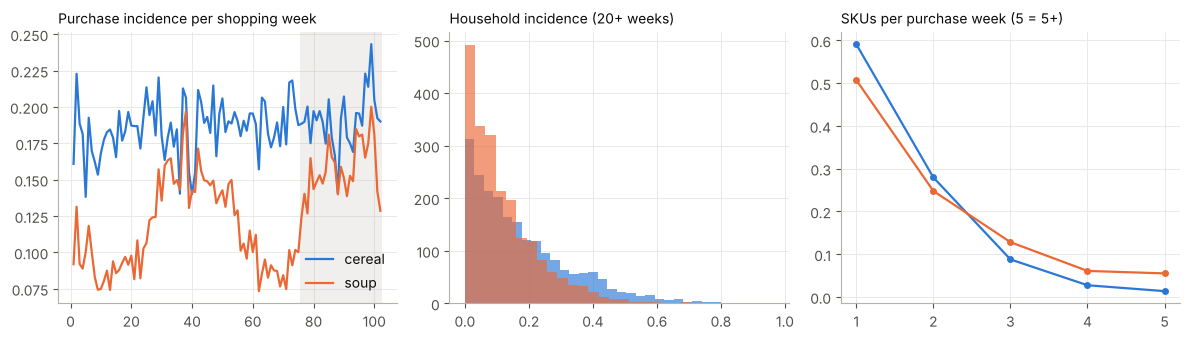

occasions  purchases  households  incidence
category split                                               
cereal   est          87899      16397        2498      0.187
         holdout      36005       6885        2433      0.191
soup     est          87899      10256        2498      0.117
         holdout      36005       5661        2433      0.157

Soup incidence shifts over time (left panel above, likely seasonal): the holdout window covers a different part of the year, so include week/season effects and compare like with like.


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for name, col in zip(CATS, C):
    o = occasions[name]
    w = o.groupby("week_no").bought.mean()
    axes[0].plot(w.index, w.values, color=col, label=name)
    hh_inc = o.groupby("household_key").bought.agg(["mean", "size"]); hh_inc = hh_inc[hh_inc["size"] >= 20]
    axes[1].hist(hh_inc["mean"], bins=30, alpha=0.65, color=col, label=name)
    vc = o[o.bought == 1].n_skus.clip(upper=5).value_counts(normalize=True).sort_index()
    axes[2].plot(vc.index, vc.values, color=col, marker="o", ms=4, label=name)
axes[0].set_title("Purchase incidence per shopping week", fontsize=10); axes[0].legend(); axes[0].axvspan(CFG["EST_END"] + 0.5, 102.5, color=GREY, alpha=0.2, lw=0)
axes[1].set_title("Household incidence (20+ weeks)", fontsize=10)
axes[2].set_title("SKUs per purchase week (5 = 5+)", fontsize=10); axes[2].set_xticks(range(1, 6))
save(fig, "10_incidence")

split_tbl = (pd.concat([occasions[n].assign(category=n) for n in CATS]).groupby(["category", "split"])
             .agg(occasions=("bought", "size"), purchases=("bought", "sum"), households=("household_key", "nunique")))
split_tbl["incidence"] = (split_tbl.purchases / split_tbl.occasions).round(3)
display(split_tbl)
for name in CATS:
    KEY[f"{name}_inc_est"] = float(split_tbl.loc[(name, "est"), "incidence"]); KEY[f"{name}_inc_ho"] = float(split_tbl.loc[(name, "holdout"), "incidence"])
print("Soup incidence shifts over time (left panel above, likely seasonal): the holdout window covers a different part of the year, so include week/season effects and compare like with like.")

### 8.1 Substitution structure preview: loyalty and brand switching

Before any model, the raw data should already show whether households differ in how loyal they are. If most households spread purchases evenly, segmenting on loyalty will not matter. If some households concentrate on one manufacturer group or one SKU, those households will transfer demand very differently after a delisting.

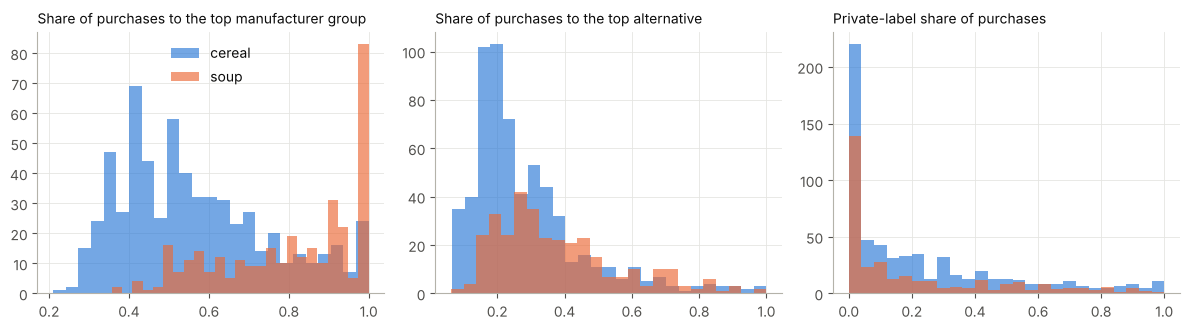

category            cereal  soup
top_mf_share  mean    0.56  0.81
              25%     0.41  0.67
              50%     0.53  0.84
              75%     0.68  0.97
top_alt_share mean    0.29  0.38
              25%     0.17  0.24
              50%     0.23  0.33
              75%     0.35  0.47
pl_share      mean    0.22  0.20
              25%     0.00  0.00
              50%     0.12  0.08
              75%     0.35  0.34


In [23]:
loy_rows = []
for name in CATS:
    o = occasions[name]; p = o[(o.bought == 1) & (o.split == "est")]
    cnt = p.groupby("household_key").size(); elig = cnt[cnt >= CFG["MIN_CAT_PURCH"]].index
    p = p[p.household_key.isin(elig)]
    top_mf = p.groupby(["household_key", "chosen_mf_group"]).size().groupby("household_key").max() / p.groupby("household_key").size()
    top_sku = p.groupby(["household_key", "chosen_alt_id"]).size().groupby("household_key").max() / p.groupby("household_key").size()
    pl = p.groupby("household_key").chosen_is_private.apply(lambda s: s.astype(float).mean())
    loy_rows.append(pd.DataFrame({"category": name, "top_mf_share": top_mf, "top_alt_share": top_sku, "pl_share": pl}))
loy = pd.concat(loy_rows)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, title in zip(axes, ["top_mf_share", "top_alt_share", "pl_share"],
                          ["Share of purchases to the top manufacturer group", "Share of purchases to the top alternative", "Private-label share of purchases"]):
    for name, c in zip(CATS, C):
        ax.hist(loy.loc[loy.category == name, col], bins=25, alpha=0.65, color=c, label=name)
    ax.set_title(title, fontsize=10)
axes[0].legend()
save(fig, "11_loyalty")
print((loy.groupby("category")[["top_mf_share", "top_alt_share", "pl_share"]].describe().T.loc[(slice(None), ["mean", "25%", "50%", "75%"]), :]).round(2))
for name in CATS:
    d = loy[loy.category == name]
    KEY[f"{name}_hh_loyal"] = int(len(d)); KEY[f"{name}_top_mf_med"] = float(d.top_mf_share.median()); KEY[f"{name}_pl_spread"] = float(d.pl_share.quantile(.9) - d.pl_share.quantile(.1))

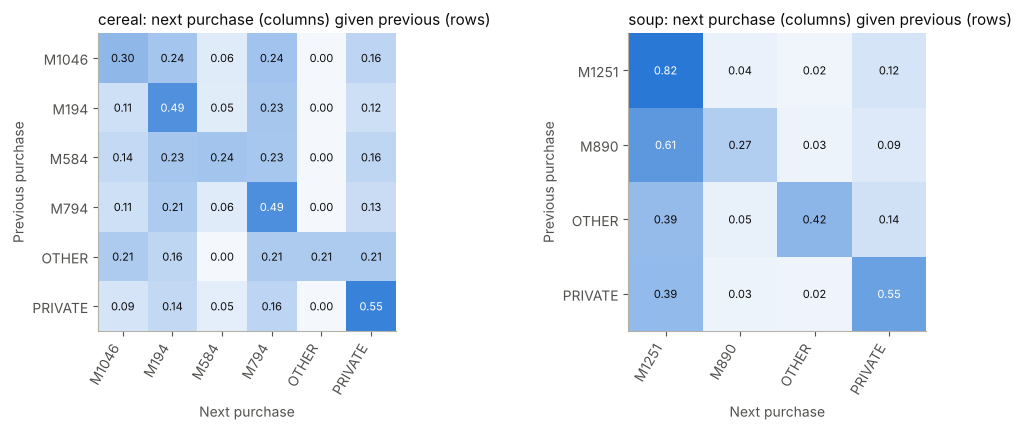

Strong diagonals mean repeat purchase within a manufacturer group. Off-diagonals show who captures demand when a household leaves its usual group.


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, name in zip(axes, CATS):
    o = occasions[name]; p = o[(o.bought == 1) & (o.split == "est")].sort_values(["household_key", "week_no"]).copy()
    p["prev"] = p.groupby("household_key").chosen_mf_group.shift()
    t = pd.crosstab(p.prev, p.chosen_mf_group, normalize="index")
    ax.imshow(t.values, cmap=SEQ, vmin=0, vmax=max(0.6, t.values.max()))
    ax.set_xticks(range(len(t.columns))); ax.set_xticklabels(t.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(t.index))); ax.set_yticklabels(t.index); ax.grid(False)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.2f}", ha="center", va="center", color=INK if t.values[i, j] < 0.45 else "white", fontsize=8)
    ax.set_title(f"{name}: next purchase (columns) given previous (rows)"); ax.set_xlabel("Next purchase"); ax.set_ylabel("Previous purchase")
    diag = np.trace(t.reindex(index=t.index, columns=t.index).fillna(0).values) / len(t)
save(fig, "12_switching_matrix")
print("Strong diagonals mean repeat purchase within a manufacturer group. Off-diagonals show who captures demand when a household leaves its usual group.")

## 9. Leakage-safe household features for segmentation

Features come **only from the estimation window and only from commodities other than cereal and soup**. If a household's cereal and soup choices helped define its segment, the segment-level choice model would partly be explaining the clusters it was built from. This part builds the feature table and examines it; clustering itself belongs to the next stage.

In [25]:
F = tx[(tx.week_no <= CFG["EST_END"]) & ~tx.commodity_desc.isin(EXCLUDED_FOR_FEATURES + ["COUPON/MISC ITEMS"])].copy()
print(f"Feature base: {len(F):,} lines from {F.household_key.nunique():,} households (estimation window, excluding {EXCLUDED_FOR_FEATURES} and COUPON/MISC ITEMS pseudo-products)")
g = F.groupby("household_key")
feat = pd.DataFrame({"trips": g.basket_id.nunique(), "shop_weeks": g.week_no.nunique(), "spend": g.sales_value.sum(), "lines": g.size()})
feat["basket_value"] = feat.spend / feat.trips
feat["items_per_basket"] = feat.lines / feat.trips
feat["trips_per_shop_week"] = feat.trips / feat.shop_weeks
feat["pl_share"] = (F[F.brand.eq("Private")].groupby("household_key").sales_value.sum().reindex(feat.index).fillna(0) / feat.spend)
F["disc_val"] = -(F.retail_disc + F.coupon_match_disc)
feat["deal_intensity"] = g.disc_val.sum() / g.gross_value.sum()
feat["promo_line_share"] = g.promo.mean()

# Price tier: percentile of a SKU's median shelf price within its commodity, spend-weighted per household
sku_p = F.groupby("product_id").agg(p=("shelf_price", "median"), n=("shelf_price", "size"), comm=("commodity_desc", "first"))
sku_p = sku_p[sku_p.n >= 5]
ok = sku_p.groupby("comm").size(); ok = ok[ok >= 15].index
sku_p = sku_p[sku_p.comm.isin(ok)]
sku_p["pct"] = sku_p.groupby("comm").p.rank(pct=True)
F["price_pct"] = F.product_id.map(sku_p.pct)
Fp = F[F.price_pct.notna() & (F.sales_value > 0)]
feat["price_tier"] = (Fp.price_pct * Fp.sales_value).groupby(Fp.household_key).sum() / Fp.sales_value.groupby(Fp.household_key).sum()

# Brand concentration: manufacturer HHI within commodities that have >= 5 manufacturers
mc = F.groupby("commodity_desc").manufacturer.nunique(); okm = mc[mc >= 5].index
H = F[F.commodity_desc.isin(okm)].groupby(["household_key", "commodity_desc", "manufacturer"]).size().rename("n").reset_index()
H["tot"] = H.groupby(["household_key", "commodity_desc"]).n.transform("sum"); H = H[H.tot >= 3]
H["sq"] = (H.n / H.tot) ** 2
hhi = H.groupby(["household_key", "commodity_desc"]).agg(h=("sq", "sum"), tot=("tot", "first")).reset_index()
feat["mf_hhi"] = (hhi.h * hhi.tot).groupby(hhi.household_key).sum() / hhi.tot.groupby(hhi.household_key).sum()

feat["eligible_seg"] = feat.trips >= CFG["MIN_TRIPS_SEG"]
feat = feat.reindex(hh.index)               # keep every household, with NaN where there is no pre-window activity
feat["eligible_seg"] = feat.eligible_seg.fillna(False)
print(f"Households with features: {feat.trips.notna().sum():,} | eligible for segmentation (>= {CFG['MIN_TRIPS_SEG']} trips): {int(feat.eligible_seg.sum()):,}")
KEY["hh_eligible_seg"] = int(feat.eligible_seg.sum())
display(feat.loc[feat.eligible_seg, ["trips", "basket_value", "items_per_basket", "trips_per_shop_week", "pl_share",
                                      "deal_intensity", "promo_line_share", "price_tier", "mf_hhi"]].describe().round(3).T)

Feature base: 1,745,429 lines from 2,497 households (estimation window, excluding ['COLD CEREAL', 'SOUP'] and COUPON/MISC ITEMS pseudo-products)


Households with features: 2,497 | eligible for segmentation (>= 20 trips): 2,039


,count,mean,std,min,25%,50%,75%,max
trips,2039.0,86.381,81.475,20.000,38.000,65.000,103.000,1033.000
basket_value,2039.0,30.883,19.584,2.601,17.774,26.206,39.068,170.265
items_per_basket,2039.0,10.603,6.148,1.342,6.293,9.213,13.376,48.298
trips_per_shop_week,2039.0,1.954,1.145,1.000,1.355,1.632,2.099,17.508
pl_share,2039.0,0.230,0.101,0.013,0.158,0.219,0.285,0.850
deal_intensity,2039.0,0.163,0.052,0.023,0.126,0.156,0.193,0.409
promo_line_share,2039.0,0.488,0.097,0.175,0.423,0.484,0.551,0.874
price_tier,2039.0,0.546,0.073,0.160,0.500,0.550,0.598,0.801
mf_hhi,2039.0,0.572,0.085,0.352,0.513,0.560,0.620,0.954


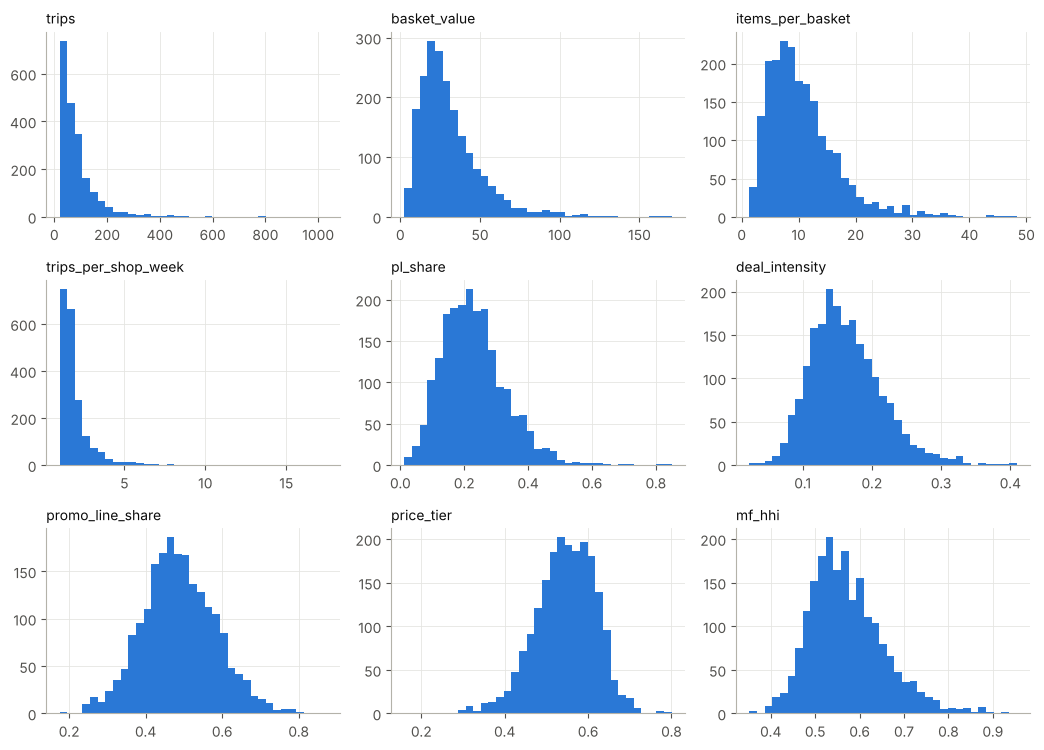

,skew,transform
trips,4.00,"log1p, then standardise"
basket_value,1.86,"log1p, then standardise"
items_per_basket,1.58,"log1p, then standardise"
trips_per_shop_week,4.78,"log1p, then standardise"
pl_share,0.89,standardise
deal_intensity,0.79,standardise
promo_line_share,0.18,standardise
price_tier,-0.42,standardise
mf_hhi,0.81,standardise


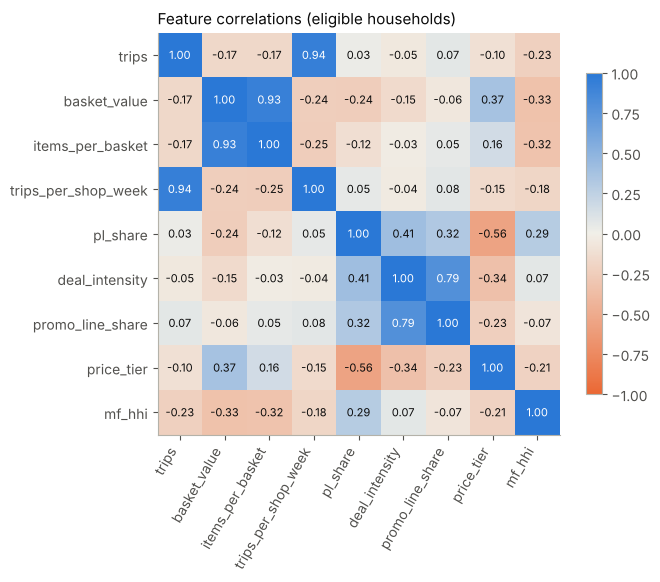

Highly correlated pairs (|r| >= 0.7), candidates to drop or combine before clustering: [('trips', 'trips_per_shop_week', 0.94), ('basket_value', 'items_per_basket', 0.93), ('deal_intensity', 'promo_line_share', 0.79)]


In [26]:
FEATS = ["trips", "basket_value", "items_per_basket", "trips_per_shop_week", "pl_share", "deal_intensity", "promo_line_share", "price_tier", "mf_hhi"]
E = feat[feat.eligible_seg]
fig, axes = plt.subplots(3, 3, figsize=(10.5, 7.6))
for ax, f in zip(axes.ravel(), FEATS):
    ax.hist(E[f].dropna(), bins=35, color=C[0]); ax.set_title(f, fontsize=10)
save(fig, "13_feature_distributions")

skew = E[FEATS].skew().round(2)
tr = pd.DataFrame({"skew": skew, "transform": np.where(skew.abs() > 1, "log1p, then standardise", "standardise")})
display(tr)

corr = E[FEATS].corr()
fig, ax = plt.subplots(figsize=(7, 5.8))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(FEATS))); ax.set_xticklabels(FEATS, rotation=60, ha="right"); ax.set_yticks(range(len(FEATS))); ax.set_yticklabels(FEATS)
for i in range(len(FEATS)):
    for j in range(len(FEATS)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(corr.values[i, j]) > 0.6 else INK)
ax.set_title("Feature correlations (eligible households)"); fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, "14_feature_correlations")
hi = [(a, b, float(round(corr.loc[a, b], 2))) for i, a in enumerate(FEATS) for b in FEATS[i + 1:] if abs(corr.loc[a, b]) >= 0.7]
print("Highly correlated pairs (|r| >= 0.7), candidates to drop or combine before clustering:", hi if hi else "none")
KEY["feat_high_corr"] = hi

## 10. Time split, eligibility and sample-size checks

The split is fixed in `CFG`: weeks 1 to 75 for estimation and 76 to 102 for the holdout. This part checks that both windows have enough data and counts the households and stores that survive each eligibility rule.

In [27]:
elig_rows = []
for name in CATS:
    o = occasions[name]
    est_p = o[(o.split == "est") & (o.bought == 1)].groupby("household_key").size()
    ho_p = o[(o.split == "holdout") & (o.bought == 1)].groupby("household_key").size()
    ok_hh = est_p[est_p >= CFG["MIN_CAT_PURCH"]].index
    seg_ok = ok_hh.intersection(feat.index[feat.eligible_seg])
    pur = o[o.bought == 1]
    st_ok = st.index[st.eligible]
    elig_rows.append(dict(category=name,
        est_purchases=int(est_p.sum()), holdout_purchases=int(ho_p.sum()),
        hh_with_est_purchase=int(len(est_p)), hh_with_10plus_est_purchases=int(len(ok_hh)),
        hh_segmentable_and_10plus=int(len(seg_ok)),
        est_purchases_by_segmentable_hh=int(est_p.reindex(feat.index[feat.eligible_seg]).dropna().sum()),
        hh_in_holdout_with_purchase=int(len(ho_p)),
        purchases_at_eligible_stores=round(float(pur.store_id.isin(st_ok).mean()), 3)))
elig = pd.DataFrame(elig_rows).set_index("category").T
display(elig)
for name in CATS:
    KEY[f"{name}_hh10"] = int(elig.loc["hh_with_10plus_est_purchases", name]); KEY[f"{name}_seg_ok"] = int(elig.loc["hh_segmentable_and_10plus", name])
    KEY[f"{name}_p_seg"] = float(elig.loc["est_purchases_by_segmentable_hh", name] / elig.loc["est_purchases", name])
    KEY[f"{name}_store_cov"] = float(elig.loc["purchases_at_eligible_stores", name]); KEY[f"{name}_est_p"] = int(elig.loc["est_purchases", name]); KEY[f"{name}_ho_p"] = int(elig.loc["holdout_purchases", name])

only_ho = set(hh.index[hh.first_week > CFG["EST_END"]])
print(f"Households first seen in the holdout window: {len(only_ho)}. All other households have estimation-window history, so segment labels can be assigned to nearly every household.")
print(f"Households active after week {CFG['EST_END']}: {(hh.last_week > CFG['EST_END']).sum():,} of {len(hh):,}")

category,cereal,soup
est_purchases,16397.000,10256.000
holdout_purchases,6885.000,5661.000
hh_with_est_purchase,2016.000,1796.000
hh_with_10plus_est_purchases,624.000,332.000
hh_segmentable_and_10plus,623.000,332.000
est_purchases_by_segmentable_hh,15904.000,9946.000
hh_in_holdout_with_purchase,1619.000,1542.000
purchases_at_eligible_stores,0.944,0.944


Households first seen in the holdout window: 2. All other households have estimation-window history, so segment labels can be assigned to nearly every household.
Households active after week 75: 2,433 of 2,500


### 10.1 Leakage ledger

| Rule | Where it is enforced |
|---|---|
| Segmentation features use weeks 1-75 only | Part 9, `F` filter |
| Segmentation features exclude cereal and soup | Part 9, `EXCLUDED_FOR_FEATURES` |
| Core-SKU threshold uses estimation-window purchase lines only | Part 5.3 |
| Availability uses each SKU's full-data lifecycle | Part 7. It describes what was on the shelf, it is not used as a predictor, but state it in the thesis |
| Inferred delisting events must be refitted on pre-event data only | Next stage (rolling origin) |
| Scalers, cluster centres and choice-model parameters fitted on the estimation window only | Next stages |

## 11. Saved outputs and data dictionary

In [28]:
hh_out = hh.reset_index().merge(feat.drop(columns=["trips", "shop_weeks", "spend"]).reset_index(), on="household_key", how="left")
hh_out = hh_out.merge(demo, on="household_key", how="left")
store_out = st.reset_index()

files = {}
for name in CATS:
    keep = ["household_key", "basket_id", "day", "week_no", "store_id", "product_id", "quantity", "sales_value", "retail_disc",
            "coupon_disc", "coupon_match_disc", "free_item", "gross_value", "shelf_price", "paid_price", "disc_share", "promo",
            "display_on", "mailer_on", "in_causal", "split"]
    files[f"lines_{name}"] = cat_lines[name][keep]
    files[f"sku_master_{name}"] = sku_master[name].reset_index()
    files[f"sku_week_{name}"] = sku_week[name]
    files[f"occasions_{name}"] = occasions[name]
files["households"] = hh_out
files["stores"] = store_out
files["inferred_events_preview"] = pd.concat([e.assign(category=n) for (n, k), e in events.items() if len(e)], ignore_index=True)
for fname, df in files.items():
    df.to_parquet(PROC / f"{fname}.parquet", index=False)
PREP_LOG["files"] = {f: dict(rows=len(d), columns=list(map(str, d.columns))) for f, d in files.items()}
with open(PROC / "prep_log.json", "w") as fh:
    json.dump(PREP_LOG, fh, indent=2, default=str)
out = pd.DataFrame({"file": [f"{f}.parquet" for f in files], "rows": [len(d) for d in files.values()],
                    "columns": [d.shape[1] for d in files.values()],
                    "size_MB": [round((PROC / f"{f}.parquet").stat().st_size / 1e6, 2) for f in files]})
display(out)

,file,rows,columns,size_MB
0,lines_cereal.parquet,37794,21,0.66
1,sku_master_cereal.parquet,634,23,0.03
2,sku_week_cereal.parquet,24565,19,0.17
3,occasions_cereal.parquet,123904,17,1.06
4,lines_soup.parquet,31693,21,0.52
5,sku_master_soup.parquet,679,23,0.03
6,sku_week_soup.parquet,27785,19,0.18
7,occasions_soup.parquet,123904,17,1.01
8,households.parquet,2500,28,0.27
9,stores.parquet,582,6,0.02


In [29]:
DD = {
 "lines_<cat>": "Purchase lines for the category (qty > 0). shelf_price = (sales_value - retail_disc - coupon_match_disc) / quantity; paid_price = sales_value / quantity; "
                "disc_share = discount as share of shelf value; promo = disc_share >= 5%; display_on/mailer_on from causal_data (partial coverage, see in_causal); split = est (weeks 1-75) or holdout.",
 "sku_master_<cat>": "One row per in-scope SKU: manufacturer, brand, sub-commodity, size_oz (parsed, imputed where size_imputed), is_private, multipack, mf_group, sub_group, size_bucket, "
                     "est_lines, core (>= 30 estimation-window lines), alt_id (SKU id if core, else pooled TAIL|mf_group|sub_group), first_week, last_week, new_in_holdout.",
 "sku_week_<cat>": "SKU x week panel inside each SKU's life: units, lines, shelf_price (observed median), shelf_price_filled (imputed, see price_observed), promo_share, disc_depth, "
                   "display_share, mailer_share, available (False inside zero-sales runs of 8+ weeks), core, alt_id, split.",
 "occasions_<cat>": "One row per household-week with at least one basket. bought = 1 if any category purchase; chosen_* describe the top-spend SKU; n_skus = distinct SKUs bought; "
                    "store_id = store of the category purchase (or main store if none); main_store_id = store with most spend that week.",
 "households": "One row per household: tenure (first_week, last_week, shop_weeks, span, fill), trips, spend, home_store/home_share, has_demo, segmentation features "
               "(estimation window, excluding cereal and soup), eligible_seg, and demographics where available.",
 "stores": "One row per store: households, baskets, spend, cum_baskets, eligible (>= 50 households).",
 "inferred_events_preview": "Chain-level candidate delisting events by category and k (zero weeks), from the Poisson rule.",
}
md_lines = ["# Data dictionary (data/processed)", ""] + [f"- **{k}**: {v}" for k, v in DD.items()]
(PROC / "data_dictionary.md").write_text("\n".join(md_lines))
print("\n".join(md_lines))

# Data dictionary (data/processed)

- **lines_<cat>**: Purchase lines for the category (qty > 0). shelf_price = (sales_value - retail_disc - coupon_match_disc) / quantity; paid_price = sales_value / quantity; disc_share = discount as share of shelf value; promo = disc_share >= 5%; display_on/mailer_on from causal_data (partial coverage, see in_causal); split = est (weeks 1-75) or holdout.
- **sku_master_<cat>**: One row per in-scope SKU: manufacturer, brand, sub-commodity, size_oz (parsed, imputed where size_imputed), is_private, multipack, mf_group, sub_group, size_bucket, est_lines, core (>= 30 estimation-window lines), alt_id (SKU id if core, else pooled TAIL|mf_group|sub_group), first_week, last_week, new_in_holdout.
- **sku_week_<cat>**: SKU x week panel inside each SKU's life: units, lines, shelf_price (observed median), shelf_price_filled (imputed, see price_observed), promo_share, disc_depth, display_share, mailer_share, available (False inside zero-sales runs of 8+ weeks), cor

## 12. Summary

In [30]:
K = KEY
ev = K["events"]
display(Markdown(f"""
### What the data shows

**Panel.** {K['households']:,} households, {K['stores']} store IDs and {K['baskets']:,} baskets over 102 weeks. {K['lines_raw'] - K['lines_clean']:,} raw lines (quantity <= 0) were removed.
The basic notebook's summary ("about 2,800 stores and 104 weeks") is wrong: use {K['stores']} stores and 102 weeks.
The panel is only fully recruited from week {K['stable_week']}, so the early weeks are noisier.

**Stores are the binding constraint.** The median store has {K['median_hh_per_store']:.0f} households. Only {K['stores_ge50']} stores have at least {CFG['STORE_MIN_HH']} households,
and they carry {K['basket_share_ge50']:.0%} of baskets. Store-level mixes, optimisation and RQ3 should be restricted to these stores, with shrinkage of segment shares.

**Demographics are a biased subset.** Only {K['hh_with_demo']} households have demographics, and they make {K['demo_trips_ratio']:.1f}x as many trips as the rest.
Demographic segmentation therefore stays a comparison on a heavy-shopper subset, not the main method.

**Categories.** Cereal: {K['cereal_skus']} SKUs, {K['cereal_core']} core alternatives ({K['cereal_alts']} after pooling the tail), {K['cereal_incidence']:.1%} purchase incidence per shopping week.
Soup (canned/ready-to-serve scope): {K['soup_skus']} SKUs, {K['soup_core']} core alternatives ({K['soup_alts']} after pooling), {K['soup_incidence']:.1%} incidence.
{K['cereal_lt5hh']} of {K['cereal_skus']} cereal SKUs and {K['soup_lt5hh']} of {K['soup_skus']} soup SKUs are bought by fewer than 5 households. SKU-level choice therefore needs attribute-based utility and a pooled tail.
Soup is dominated by one manufacturer group, so only four manufacturer groups exist. The sub-commodity (condensed vs ready-to-serve) and private label carry most of the substitution structure.

**Prices and promotions.** Shelf prices barely vary across stores, so chain-wide weekly shelf prices are used for non-purchased alternatives.
{K['cereal_promo']:.0%} of cereal and {K['soup_promo']:.0%} of soup purchase lines are promoted. `causal_data` covers only {K['cereal_promo_in_causal']:.0%} (cereal) and {K['soup_promo_in_causal']:.0%} (soup) of promoted lines, so the discount-based flag is primary.
Soup promotion intensity swings strongly over time (likely seasonal), and soup incidence is {K['soup_inc_est']:.1%} in the estimation window against {K['soup_inc_ho']:.1%} in the holdout. Include week or season effects, or the holdout comparison will be confounded.

**Estimation sample.** Estimation-window purchase occasions: cereal {K['cereal_est_p']:,}, soup {K['soup_est_p']:,}. Segmentable households (>= {CFG['MIN_TRIPS_SEG']} trips) account for {K['cereal_p_seg']:.0%} (cereal) and {K['soup_p_seg']:.0%} (soup) of those purchases.
Only {K['cereal_hh10']:,} (cereal) and {K['soup_hh10']:,} (soup) households have {CFG['MIN_CAT_PURCH']}+ estimation-window category purchases. Earlier screening counted purchase *lines* across all 102 weeks, which is why those numbers were larger.
Do not drop households below 10 purchases from the choice models. Keep every segmentable household and use purchases per segment as the sample-size check.

**Validation feasibility.** Chain-level inferred delisting events: cereal {ev['cereal_k4']} (k = 4) to {ev['cereal_k8']} (k = 8); soup {ev['soup_k4']} (k = 4) to {ev['soup_k8']} (k = 8).
Cereal supports pooled RQ2 evidence. Soup is thin at k = 4, so RQ2 for soup needs k >= 6 or pooled reporting with cereal. Store-level events will be fewer still.

**Segmentation features.** {K['hh_eligible_seg']:,} households are segmentable. Highly correlated feature pairs: {K['feat_high_corr']}.
A sensible starting set is `basket_value`, `trips_per_shop_week`, `pl_share`, `deal_intensity`, `price_tier` and `mf_hhi` (log-transform the first two). Drop `trips` (tenure-driven), `items_per_basket` and `promo_line_share`, which duplicate other features.

### Decisions made here that the thesis should state

1. Choice occasion = household shopping week, outside option = shopping week with no category purchase.
2. Soup is restricted to canned, ready-to-serve and microwavable sub-commodities (about 78% of soup revenue). Dry soup, broth, bouillon and ramen are excluded. Test this as a sensitivity.
3. SKUs with fewer than {CFG['CORE_MIN_LINES']} estimation-window purchase lines are pooled into tail alternatives by manufacturer group and sub-commodity.
4. Availability is chain-wide and inferred from SKU life and sales gaps. Store-level availability is not observable.
5. The discount-based promo flag (>= {CFG['PROMO_THRESH']:.0%}) is primary. Display and mailer are secondary controls with partial coverage.
6. Segmentation features use weeks 1-{CFG['EST_END']} and exclude cereal, soup and coupon pseudo-products.

### Next stage
Fit the pooled multinomial logit on `occasions_cereal` + `sku_week_cereal` as the baseline, then cluster `households.parquet` (eligible households, log-transformed, standardised).
"""))


### What the data shows

**Panel.** 2,500 households, 582 store IDs and 275,889 baskets over 102 weeks. 14,466 raw lines (quantity <= 0) were removed.
The basic notebook's summary ("about 2,800 stores and 104 weeks") is wrong: use 582 stores and 102 weeks.
The panel is only fully recruited from week 16, so the early weeks are noisier.

**Stores are the binding constraint.** The median store has 2 households. Only 104 stores have at least 50 households,
and they carry 94% of baskets. Store-level mixes, optimisation and RQ3 should be restricted to these stores, with shrinkage of segment shares.

**Demographics are a biased subset.** Only 801 households have demographics, and they make 2.7x as many trips as the rest.
Demographic segmentation therefore stays a comparison on a heavy-shopper subset, not the main method.

**Categories.** Cereal: 634 SKUs, 207 core alternatives (227 after pooling the tail), 18.8% purchase incidence per shopping week.
Soup (canned/ready-to-serve scope): 679 SKUs, 167 core alternatives (178 after pooling), 12.8% incidence.
349 of 634 cereal SKUs and 381 of 679 soup SKUs are bought by fewer than 5 households. SKU-level choice therefore needs attribute-based utility and a pooled tail.
Soup is dominated by one manufacturer group, so only four manufacturer groups exist. The sub-commodity (condensed vs ready-to-serve) and private label carry most of the substitution structure.

**Prices and promotions.** Shelf prices barely vary across stores, so chain-wide weekly shelf prices are used for non-purchased alternatives.
62% of cereal and 38% of soup purchase lines are promoted. `causal_data` covers only 37% (cereal) and 33% (soup) of promoted lines, so the discount-based flag is primary.
Soup promotion intensity swings strongly over time (likely seasonal), and soup incidence is 11.7% in the estimation window against 15.7% in the holdout. Include week or season effects, or the holdout comparison will be confounded.

**Estimation sample.** Estimation-window purchase occasions: cereal 16,397, soup 10,256. Segmentable households (>= 20 trips) account for 97% (cereal) and 97% (soup) of those purchases.
Only 624 (cereal) and 332 (soup) households have 10+ estimation-window category purchases. Earlier screening counted purchase *lines* across all 102 weeks, which is why those numbers were larger.
Do not drop households below 10 purchases from the choice models. Keep every segmentable household and use purchases per segment as the sample-size check.

**Validation feasibility.** Chain-level inferred delisting events: cereal 31 (k = 4) to 49 (k = 8); soup 6 (k = 4) to 20 (k = 8).
Cereal supports pooled RQ2 evidence. Soup is thin at k = 4, so RQ2 for soup needs k >= 6 or pooled reporting with cereal. Store-level events will be fewer still.

**Segmentation features.** 2,039 households are segmentable. Highly correlated feature pairs: [('trips', 'trips_per_shop_week', 0.94), ('basket_value', 'items_per_basket', 0.93), ('deal_intensity', 'promo_line_share', 0.79)].
A sensible starting set is `basket_value`, `trips_per_shop_week`, `pl_share`, `deal_intensity`, `price_tier` and `mf_hhi` (log-transform the first two). Drop `trips` (tenure-driven), `items_per_basket` and `promo_line_share`, which duplicate other features.

### Decisions made here that the thesis should state

1. Choice occasion = household shopping week, outside option = shopping week with no category purchase.
2. Soup is restricted to canned, ready-to-serve and microwavable sub-commodities (about 78% of soup revenue). Dry soup, broth, bouillon and ramen are excluded. Test this as a sensitivity.
3. SKUs with fewer than 30 estimation-window purchase lines are pooled into tail alternatives by manufacturer group and sub-commodity.
4. Availability is chain-wide and inferred from SKU life and sales gaps. Store-level availability is not observable.
5. The discount-based promo flag (>= 5%) is primary. Display and mailer are secondary controls with partial coverage.
6. Segmentation features use weeks 1-75 and exclude cereal, soup and coupon pseudo-products.

### Next stage
Fit the pooled multinomial logit on `occasions_cereal` + `sku_week_cereal` as the baseline, then cluster `households.parquet` (eligible households, log-transformed, standardised).
